# Week 10：RAG 系列
單張 RTX 3090 24GB · 所有圖片存到 `Outputs/Q{n}_*.png`，所有索引 / 圖譜 / 設定存到 `Outputs/q{n}_*`

| 專案結構 | 說明 |
|---|---|
| `main.ipynb` | 本檔：逐步展示（前處理 → 實驗 → 結果），每個結果 cell 後面都有「📊 結果解讀」 |
| `Codes/common.py` | 共用：模型封裝 (Qwen2.5-7B / Qwen2.5-VL-7B / bge-m3)、LLM-judge、指標、存圖 |
| `Codes/Quiz1.py` ~ `Quiz4.py` | 各 Quiz 的函式；`Codes/asr_worker.py` 在子行程執行 ASR |
| `Data/` | 自動下載 / 生成的資料（Wikipedia 語料、QA、論文 PDF、影片放在 `Data/q2_videos/`） |
| `Outputs/` | 圖片與模型檔 |

**GPU 記憶體管理**：一次只放一個 7B 模型，切換 Quiz 時用 `release()` 釋放。實測顯存（torch allocated）：
`ChatLLM` 15.2 GB、`VLM` 16.5 GB、VLM + bge-m3 + Chinese-CLIP 同時載入 17.3 GB，都在 24 GB 內。
**沒有任何訓練步驟**（全部使用預訓練模型做推論 / 檢索），因此不需要 early stopping；
若之後加入 reranker / 融合權重的微調，記得加上 `EarlyStopping`。

> **ASR 備註**：環境的 torch 是 CUDA 13 版，faster-whisper（CTranslate2）需要 CUDA 12 的 `libcublas.so.12` 而無法在 GPU 執行；
> `asr_worker.py` 會自動改用 transformers 的 `whisper-large-v3-turbo`（使用 torch 自帶的 CUDA），所以 Quiz 2 的逐字稿是正常的。

In [1]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"   # 減少顯存碎片化 OOM
os.environ["CUDA_VISIBLE_DEVICES"] = "1"   # 改成你要用的那張卡的編號，例如 "1"

import sys, json, warnings

from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / "Codes").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown

from Codes.common import *
from Codes import Quiz1 as Q1, Quiz2 as Q2, Quiz3 as Q3, Quiz4 as Q4

pd.set_option("display.max_colwidth", 120)
seed_everything(42)
gpu_report(" at start")
print("ROOT =", ROOT)

[GPU] at start torch-allocated 0.0 GB | device used 0.3 / 23.6 GB
ROOT = /cluster/home/m315832001/class/MMIP/week10


# Quiz 1 — 多輪對話 RAG
**主題**：人工智慧 / 機器學習（繁中維基百科 **29 篇**，共 136,392 字）。
流程：Wikipedia 下載 → 句子感知切塊 → bge-m3 向量 → 餘弦檢索 → **多輪查詢改寫** → Prompting → 答案 + 引用 (Reference)。

## Q1.1 前處理：下載語料

,0,1,2,3,4,5,6,7,8,9,...,19,20,21,22,23,24,25,26,27,28
doc_id,D00,D01,D02,D03,D04,D05,D06,D07,D08,D09,...,D19,D20,D21,D22,D23,D24,D25,D26,D27,D28
title,人工智慧,機器學習,深度學習,人工神經網路,自然語言處理,大型語言模型,卷積神經網路,迴圈神經網路,強化學習,監督學習,...,知識圖譜,圖靈測試,ChatGPT,反向傳播演算法,過適,梯度下降法,貝葉斯定理,邏輯斯諦迴歸,線性回歸,隨機森林
chars,15508,7658,7398,6186,4729,9840,2869,3211,2590,1838,...,2936,1926,10547,4363,1983,1372,3859,1768,3979,4697


29 documents, 136,392 characters


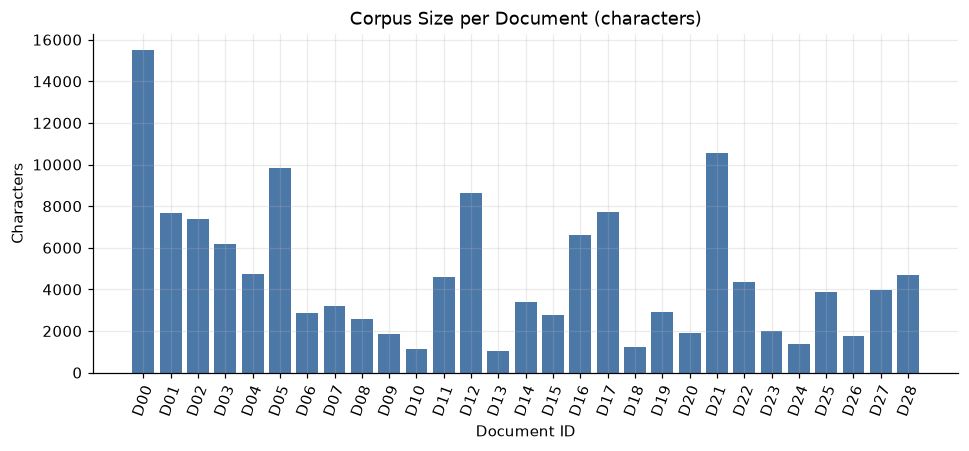

[saved] /cluster/home/m315832001/class/MMIP/week10/Outputs/Q1_corpus_chars_per_document.png


In [2]:
corpus = Q1.download_corpus()
display(pd.DataFrame([{"doc_id": d["doc_id"], "title": d["title"], "chars": len(d["text"])} for d in corpus]).T)
print(f"{len(corpus)} documents, {sum(len(d['text']) for d in corpus):,} characters")
Q1.plot_corpus_stats(corpus);

**觀察**
* `WIKI_TITLES` 共 32 個條目，成功下載 **29 篇、136,392 字**；`非監督式學習`、`特徵工程`、`遷移學習` 內文不到 800 字被略過。
  下載時每次請求間隔 1 秒，遇到維基的流量限制（HTTP 429）會自動等待重試（第一次執行只抓到前 10 篇就是被限流）。
* 已安裝 `opencc`，標題與內文都是**繁體**（例如 `人工智慧`、`迴圈神經網路`）。
* 篇幅差距很大：最長 `人工智慧` 15,508 字、最短 `推薦系統` 1,022 字（約 15 倍），所以 Q1.6 用 macro 平均（每篇文件分開算命中率再平均），避免長文件主導結果。

## Q1.2 前處理：切塊（Embedding 數量 ≥ 200）

number of chunks (= embeddings): 562
人工智慧 | 人工智慧（英語：artificial intelligence，縮寫為AI）指讓電腦完成那些以往需要人類智慧才能應付的任務，比如學習、推理、解決問題、感知和決策。它橫跨工程學、數學和電腦科學，目標是研究並開發相關方法和軟體，讓機器能感知環境 …


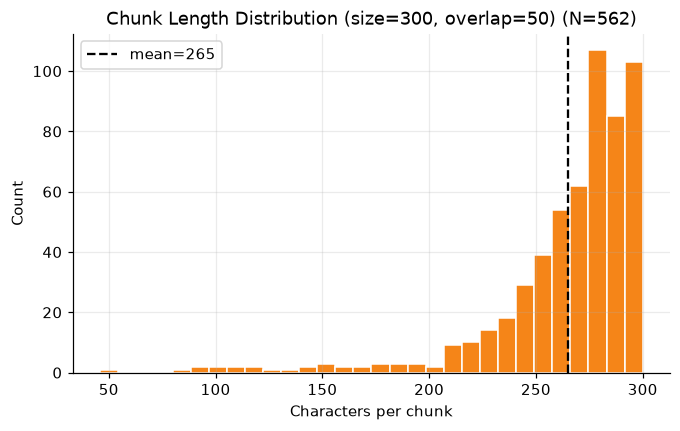

[saved] /cluster/home/m315832001/class/MMIP/week10/Outputs/Q1_chunk_length_distribution.png


In [3]:
chunks = Q1.build_chunks(corpus, chunk_size=300, overlap=50)      # 預設設定，進階實驗會再找最佳值
print("number of chunks (= embeddings):", len(chunks))
assert len(chunks) >= 200, "Embedding 數量不足 200，請增加 Q1.WIKI_TITLES 或縮小 chunk_size"
print(chunks[0]["title"], "|", chunks[0]["text"][:120], "…")
Q1.plot_chunk_stats(chunks, "(size=300, overlap=50) ");

**觀察**

* 預設切塊（300 字 / overlap 50）得到 **562 個 chunk（= 562 個 embedding），達成 ≥ 200 的要求**；長度大多集中在 300 字附近（句子感知切塊不會把句子切一半）。

## Q1.3 前處理：Embedding 與向量索引

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Batches:   0%|          | 0/18 [00:00<?, ?it/s]

embedding matrix: (562, 1024)
[saved] /cluster/home/m315832001/class/MMIP/week10/Outputs/q1_index_default.npz + q1_index_default_chunks.json


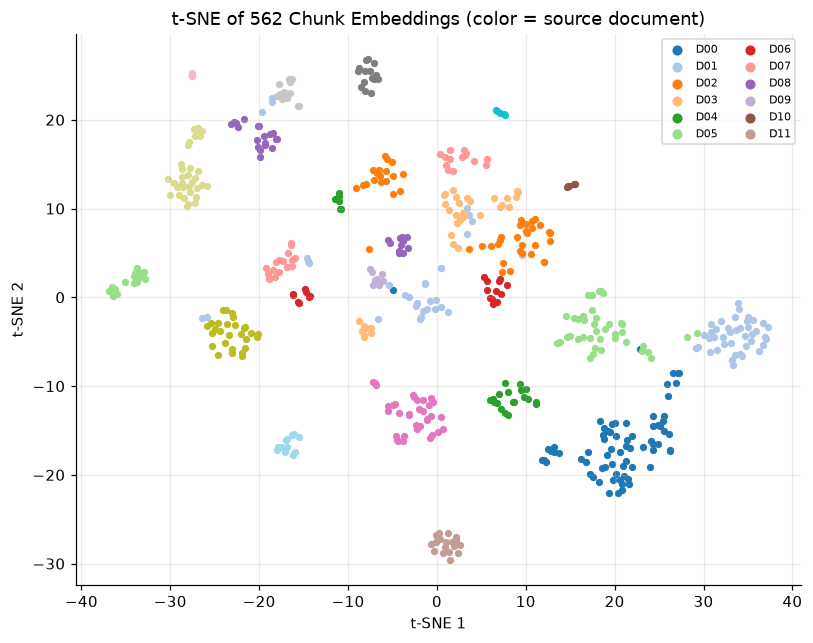

[saved] /cluster/home/m315832001/class/MMIP/week10/Outputs/Q1_chunk_embedding_tsne.png


In [4]:
embedder = Embedder() # BAAI/bge-m3
index = Q1.VectorIndex.build(chunks, embedder, show=True)
print("embedding matrix:", index.emb.shape)
index.save("q1_index_default")
Q1.plot_embedding_space(index);

**觀察**

* 向量矩陣 `(562, 1024)`（bge-m3）。t-SNE 圖中同一篇文件的 chunk 大多聚成一群；語意相近的文章（深度學習 / 人工神經網路 / 卷積神經網路）彼此靠近，
  機器學習（D01）的 chunk 則散布在多群之間，因為它與很多主題都有關。代表 embedding 品質合理，但相近主題之間可能互相誤檢索。
* 圖例只列前 12 篇；29 篇共用 20 色調色盤，所以有些顏色會重複出現。

## Q1.4 自製 QA Dataset（LLM 出題 + 證據逐字驗證）
每題含 `question / answer / evidence / ev_start / ev_end`，證據必須是原文的逐字片段，才能用字元位置自動判斷檢索是否命中。

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

[GPU] after LLM torch-allocated 15.2 GB | device used 15.6 / 23.6 GB
[QA] kept 120 / 264 candidates -> /cluster/home/m315832001/class/MMIP/week10/Data/q1_qa_dataset.json
[QA] dropped: {'format': 53, 'pronoun / context-dependent': 3, 'not standalone': 27, 'not supported': 2}  (rejected items saved to Data/q1_qa_rejected.json for manual review)
[MT] kept 38 multi-turn items (26 pronoun follow-ups + 12 topic switches) -> /cluster/home/m315832001/class/MMIP/week10/Data/q1_multiturn_dataset.json


,id,title,question,answer,evidence
0,qa000,人工智慧,什麼時候開始，深度學習成為人工智慧領域廣泛採用的方法？,2012年以來,2012年以來，深度學習開始主導行業標準，並迅速成為該領域廣泛採用的方法。
1,qa001,機器學習,什麼是學習器的核心目標之一？,學習器的核心目標之一是從經驗中進行泛化。,學習器（learner）的核心目標之一是從經驗中進行泛化（generalize）。
2,qa002,深度學習,深度學習技術缺乏哪些重要能力？,缺乏表達因果關係的手段，缺乏進行邏輯推理的方法，遠沒有具備整合抽象知識，例如物品屬性、代表和典型用途的資訊。,這些技術缺乏表達因果關係的手段……缺乏進行邏輯推理的方法，而且遠沒有具備整合抽象知識，例如物品屬性、代表和典型用途的資訊。
3,qa003,自然語言處理,什麼理論的架構不傾向於語料庫，而被認為不適合機器學習處理語言的方法？,喬姆斯基語言學理論,該理論的架構不傾向於語料庫——機器學習處理語言所用方法的基礎。
4,qa004,大型語言模型,大型語言模型在哪些任務中通常能夠表現出色？,即使在沒有針對特定任務（例如情感分析、命名實體辨識、文字翻譯、摘要生成或數學推理）進行訓練的情況下，LLM往往也能夠在這些任務中表現出色。,由於大語言模型的記憶和泛化能力強大，其通常能用作通用模型：即使在沒有針對特定任務（例如情感分析、命名實體辨識、文字翻譯、摘要生成或數學推理）進行訓練的情況下，LLM往往也能夠在這些任務中表現出色。
5,qa005,卷積神經網路,什麼是池化層的主要功能？,池化層的主要功能是降低卷積層對邊緣的敏感性，並減少資料量。,池化層每次在一個池化視窗（depth slice）上計算輸出，然後根據步幅移動池化視窗。下圖是目前最常用的池化層，步幅為2，池化視窗為2×2的二維最大池化層。每隔2個元素從影象劃分出2×2的區塊，然後對每個區塊中的4個數取最大值。這...
6,qa006,迴圈神經網路,什麼時候LSTM開始革新語音識別領域？,大約在2007年,大約在2007年，LSTM開始革新語音識別領域，在某些語音應用中勝過傳統模型。
7,qa007,強化學習,強化學習中，哪種方法會以較大的機率選擇當前最優的動作？,ϵ-貪婪演演演算法,其中的一種方法就是 ϵ-貪婪演演算法，這種方法會以比較大的機率(1-ϵ)去選擇現在最好的動作。


,followup,standalone,answer
0,那它的缺點呢？,喬姆斯基語言學理論的缺點是什麼？,喬姆斯基語言學理論的架構不傾向於語料庫，這使得它不太適合機器學習處理語言的方法。
1,那它的缺點呢？,深度學習的主要缺點是什麼？,深度學習的主要批評是許多方法缺乏理論支撐。大多數深度結構僅僅是梯度下降的某些變式。
2,那它會不會只根據評分來推薦？,推薦系統會不會只根據評分來推薦？,不是的，推薦系統不僅根據評分，還會考慮使用者的偏好。
3,那它的缺點呢？,強化學習的缺點是什麼？,強化學習的缺點包括需要大量的資料和計算資源，並且學習過程可能非常緩慢，尤其是在探索最佳策略時。
4,那它的缺點呢？,支援向量機的缺點有哪些？,支援向量機的主要缺點之一是對於大型資料集的訓練時間較長，因為需要計算核函式的值。此外，選擇合適的核函式和引數也需要一定的技巧和經驗。


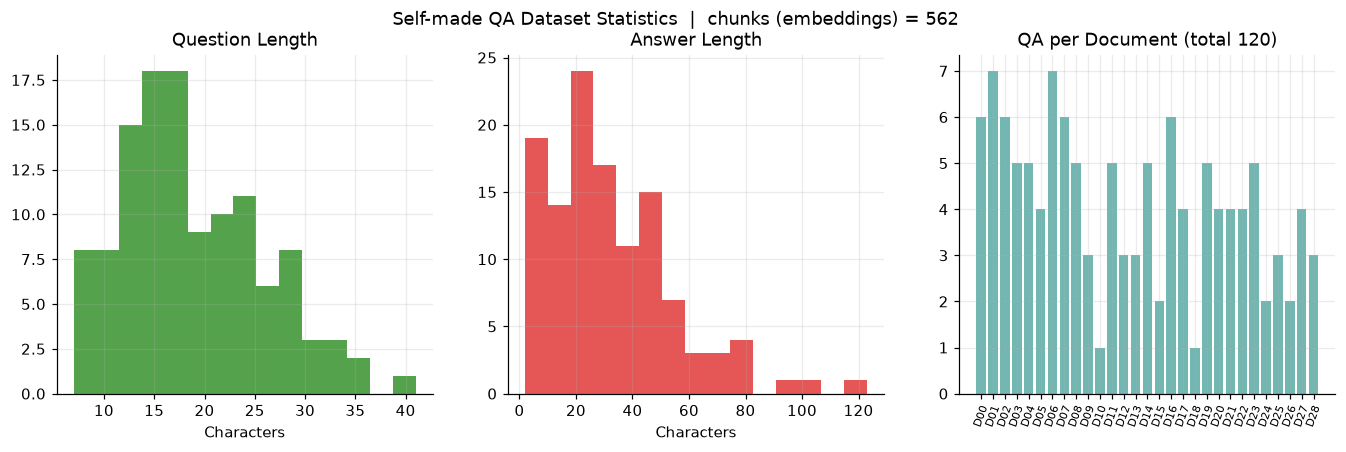

[saved] /cluster/home/m315832001/class/MMIP/week10/Outputs/Q1_qa_dataset_statistics.png


In [5]:
llm = ChatLLM() # Qwen2.5-7B-Instruct
gpu_report(" after LLM")
qa = Q1.generate_qa_dataset(llm, corpus, n_target=120)
mt = Q1.generate_multiturn_dataset(llm, corpus, qa, n_target=40)
display(pd.DataFrame(qa)[["id", "title", "question", "answer", "evidence"]].head(8))
display(pd.DataFrame([{"followup": m["followup"], "standalone": m["standalone"], "answer": m["answer"]} for m in mt]).head(5))
Q1.plot_qa_stats(qa, chunks);

**觀察**

* **QA 資料集 120 題**（264 個候選）。三道過濾：
  1. 格式 / 證據不是原文逐字片段：剔除 53 題；
  2. 規則過濾「第一句 / 這個例子 / 它…」等依賴上下文的問題：剔除 3 題；
  3. **LLM 自我檢查**（問題是否獨立、證據是否支持答案）：判為不獨立 27 題、答案不被證據支持 2 題。被剔除的題目存在 `Data/q1_qa_rejected.json` 供人工抽查。
* 自我檢查偏嚴格：被剔除的題目中也有其實可以獨立理解的（如「人工神經網路的輸出是否線性？」），寧可錯殺以確保保留下來的題目品質。
  這次保留的題目都是繁體、可獨立理解（如「強化學習中，哪種方法會以較大的機率選擇當前最優的動作？」→ ϵ-貪婪演算法）。
* **多輪資料集 38 題**，兩種類型：
  * **26 題代名詞追問**（同主題，例如「那它的缺點呢？」→ 獨立問題「支援向量機的缺點有哪些？」），必須靠第一輪才知道在問什麼；
  * **12 題換主題**（第一輪問文件 A，第二輪改問文件 B，例如「人工智慧通常指的是什麼？」→「什麼是電腦視覺的核心任務？」），這時對話歷史只是雜訊。
  加入換主題的題目，才能公平比較「歷史串接」與「查詢改寫」（見 Q3.A.3）。

## Q1.5 展示：多輪對話 Context 經過 RAG 得到合理回覆與 Reference
第 2、3、4 輪都用代名詞追問（「它」「其中」），系統先把問題**改寫成獨立查詢**再檢索。

In [6]:
chat = Q1.RAGChat(llm, index, top_k=5, technique="grounded_strict", rewrite=True)
demo_results = Q1.run_demo_conversation(chat)


===== Turn 1 =====
👤 什麼是深度學習？
🤖 深度學習是機器學習的一種，以人工神經網路為基礎，通過多層結構對資料進行表徵學習。[1]
📎 References:
   [1] ✔ cited | D02 深度學習 | score=0.782 | 深度學習（英語：deep learning）是機器學習的分支，是一種以人工神經網路為架構，對資料進行表徵學習的演演算法。深度學習中的形容詞「深度」是指在網路中使用多層。 早期的工作表明，線性感知器不能成為通用分類器，但具有非多項式啟用功能和一個無限寬度隱藏層的網路可以成為通用分類器。 深度學習是機器學習中一種基於對資料…
   [2]   retrieved | D01 機器學習 | score=0.711 | 醫學診斷（medical diagnosis） 這些成功應用證明瞭神經網路在解決複雜、非線性問題方面的強大能力。 深度學習（Deep Learning）是指在類神經網路中引入多個隱藏層（hidden layers）的一種方法。這種方法試圖類比人腦將光和聲音轉化為視覺和聽覺的處理方式。深度學習在多個領域取得了顯著成果，其…
   [3]   retrieved | D02 深度學習 | score=0.698 | 深度學習常常被看作是通向真正人工智慧的重要一步，因而許多機構對深度學習的實際應用抱有濃厚的興趣。2013年12月，Facebook宣佈僱用楊立昆為其新建的人工智慧實驗室的主管，這一實驗室將在加州、倫敦和紐約設立分支機構，幫助Facebook研究利用深度學習演演算法進行類似自動標記相片中使用者姓名這樣的任務。 2013年…
   [4]   retrieved | D02 深度學習 | score=0.694 | 谷歌同時併購了辛頓創辦的公司DNNresearch。 2016年3月，以深度學習開發的圍棋程式AlphaGo首度在比賽中擊敗人類頂尖選手，形成廣泛的討論。 對深度學習的主要批評是許多方法缺乏理論支撐。大多數深度結構僅僅是梯度下降的某些變式。儘管梯度下降法已經被充分地研究，但理論涉及的其他演演算法，例如對比分歧演演算法，…
   [5]   retrieved | D02 深度學習 | score=0.674 | 儘管深度學習的能力很強，但和真正的人工智慧相比，仍然缺乏諸多重要的能力

**觀察**

* **多輪 Context 有成功帶過 RAG**：第 2 輪「它跟傳統機器學習有什麼不同？」被改寫成「深度學習和傳統機器學習有什麼不同？」再檢索，
  引用的都是 `深度學習` 文件；第 3 輪「那它常用的神經網路架構」還原為「深度學習常用的神經網路架構」；
  第 4 輪「其中卷積神經網路…」改寫成獨立問題後，References 全部來自 `卷積神經網路`（D06），回答「影像和語音辨識、視訊分析、自然語言處理」。
* 每個答案都帶 `[n]` 引用，並列出被引用（✔）/ 僅被檢索的 chunk 與相似度，Reference 可追溯。
* 小問題：第 2 輪改寫後的查詢是簡體（「深度学习和传统机器学习…」），因為改寫模型偶爾輸出簡體；bge-m3 是多語模型，不影響檢索結果。

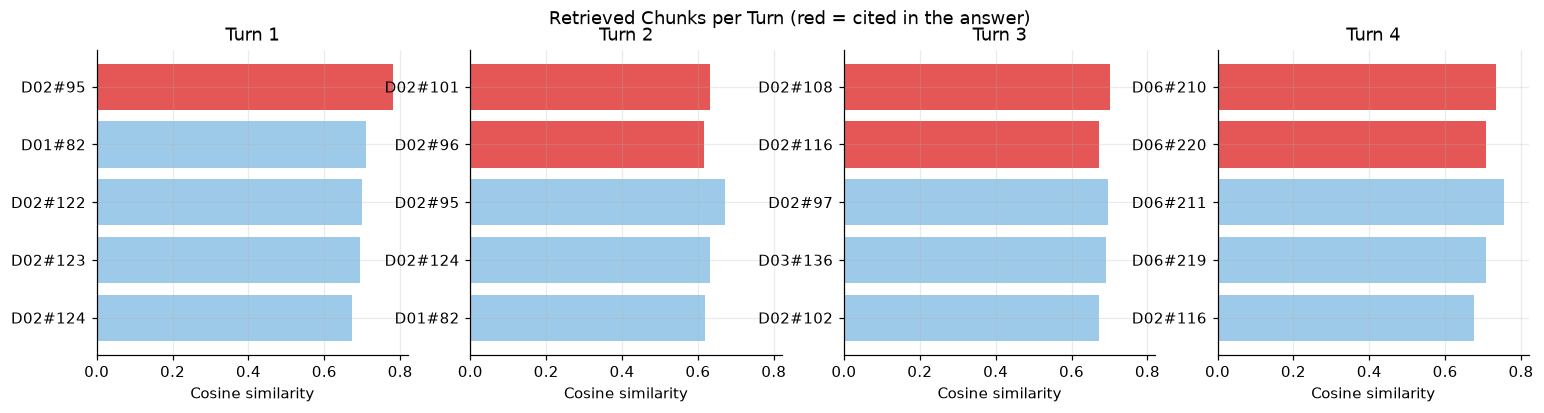

[saved] /cluster/home/m315832001/class/MMIP/week10/Outputs/Q1_demo_retrieval_scores.png


In [7]:
Q1.plot_demo_retrieval(demo_results);

## Q1.6 進階 ①：找出最穩定的 Chunk Size / Overlap / Top-K
* **命中判定**：檢索到的 chunk 與黃金證據在同一篇文件且覆蓋 ≥50% 證據字元（以字元位置計算 → 不同 chunk size 可公平比較）。
* **穩定性**：`hit_macro` 為各文件命中率的平均；`std_doc` 為跨文件標準差（越小越穩）；`ci_low` 為 bootstrap 5% 分位；
  `score = 0.5 × hit_macro + 0.5 × MRR − std_doc − 0.05 × (context 千字數)`。K 大時 Hit@K 幾乎都是 1.0（飽和），
  所以把 MRR（正確 chunk 排得多前面）放進分數；同時懲罰不穩定與過長的 context。

In [8]:
df_rank = Q1.run_chunk_grid(corpus, qa, embedder, chunk_sizes=(150, 300, 500, 800), overlaps=(0, 50, 100, 150), max_k=10)
summary = Q1.summarize_grid(df_rank, ks=(1, 3, 5, 8, 10))
summary.to_csv(OUT_DIR / "q1_grid_summary.csv", index=False)
display(summary.sort_values("score", ascending=False).head(10).round(3))

[grid] chunk= 150 overlap=  0 -> 1120 chunks
[grid] chunk= 150 overlap= 50 -> 1363 chunks
[grid] chunk= 300 overlap=  0 -> 516 chunks
[grid] chunk= 300 overlap= 50 -> 562 chunks
[grid] chunk= 300 overlap=100 -> 689 chunks
[grid] chunk= 300 overlap=150 -> 890 chunks
[grid] chunk= 500 overlap=  0 -> 301 chunks
[grid] chunk= 500 overlap= 50 -> 315 chunks
[grid] chunk= 500 overlap=100 -> 352 chunks
[grid] chunk= 500 overlap=150 -> 385 chunks
[grid] chunk= 800 overlap=  0 -> 191 chunks
[grid] chunk= 800 overlap= 50 -> 196 chunks
[grid] chunk= 800 overlap=100 -> 202 chunks
[grid] chunk= 800 overlap=150 -> 217 chunks


,chunk_size,overlap,k,hit_micro,hit_macro,std_doc,ci_low,mrr,ctx_chars,n_chunks,hit1,score
9,150,50,10,0.992,0.994,0.031,0.975,0.754,1200.154,1363,0.642,0.783
3,150,0,8,0.983,0.986,0.048,0.967,0.750,970.300,1120,0.642,0.771
8,150,50,8,0.983,0.985,0.056,0.958,0.753,960.123,1363,0.642,0.765
4,150,0,10,0.983,0.986,0.048,0.966,0.750,1212.875,1120,0.642,0.759
28,300,150,8,0.975,0.982,0.050,0.950,0.764,2139.272,890,0.650,0.716
29,300,150,10,0.992,0.994,0.031,0.975,0.765,2674.090,890,0.650,0.714
7,150,50,5,0.933,0.941,0.102,0.892,0.746,600.077,1363,0.642,0.711
18,300,50,8,0.983,0.983,0.059,0.967,0.746,2120.470,562,0.617,0.699
23,300,100,8,0.975,0.976,0.069,0.950,0.757,2127.861,689,0.617,0.691
24,300,100,10,0.983,0.983,0.059,0.967,0.758,2659.826,689,0.617,0.678


**觀察**

K = 8 時各設定的比較（`score = 0.5 × hit_macro + 0.5 × MRR − std_doc − 0.05 × context 千字數`）：

| chunk / overlap | Hit@1 | MRR | std_doc | context 字數 | score |
|---|---|---|---|---|---|
| **150 / 0** | 0.642 | 0.750 | 0.048 | **970** | **0.771** |
| 150 / 50 | 0.642 | 0.753 | 0.056 | 960 | 0.765 |
| 300 / 150 | **0.650** | **0.764** | 0.050 | 2,139 | 0.716 |
| 300 / 50 | 0.617 | 0.746 | 0.059 | 2,120 | 0.699 |
| 500 / 0 | 0.625 | 0.754 | **0.031** | 3,621 | 0.661 |
| 800 / 150 | 0.617 | 0.749 | 0.061 | 5,849 | 0.512 |

* **語料擴大到 29 篇後，Hit@K 的天花板效應消失了**：Hit@1 只有 0.58–0.67、Hit@3 約 0.85–0.90，各設定之間開始有差異；K = 8 時 Hit 仍有 0.96–0.99。
* **各 chunk size 的排序品質其實很接近**（MRR 0.70–0.77、Hit@1 0.58–0.67），真正拉開分數的是 **context 長度**：
  K = 8 時 chunk 150 只要約 970 字，chunk 800 要約 5,800 字。所以 **chunk 150 綜合最佳**——用最少的 context 達到差不多的命中率。
* Overlap 的影響不一致（chunk 300 是 overlap 150 最好、chunk 500 是 overlap 0 最好），不宜解讀為規律。
* ⚠️ 120 題下 1 題 ≈ 0.008；各設定的 Hit@1 差距大多在 0.05 以內，score 的排序主要由 context 成本決定。

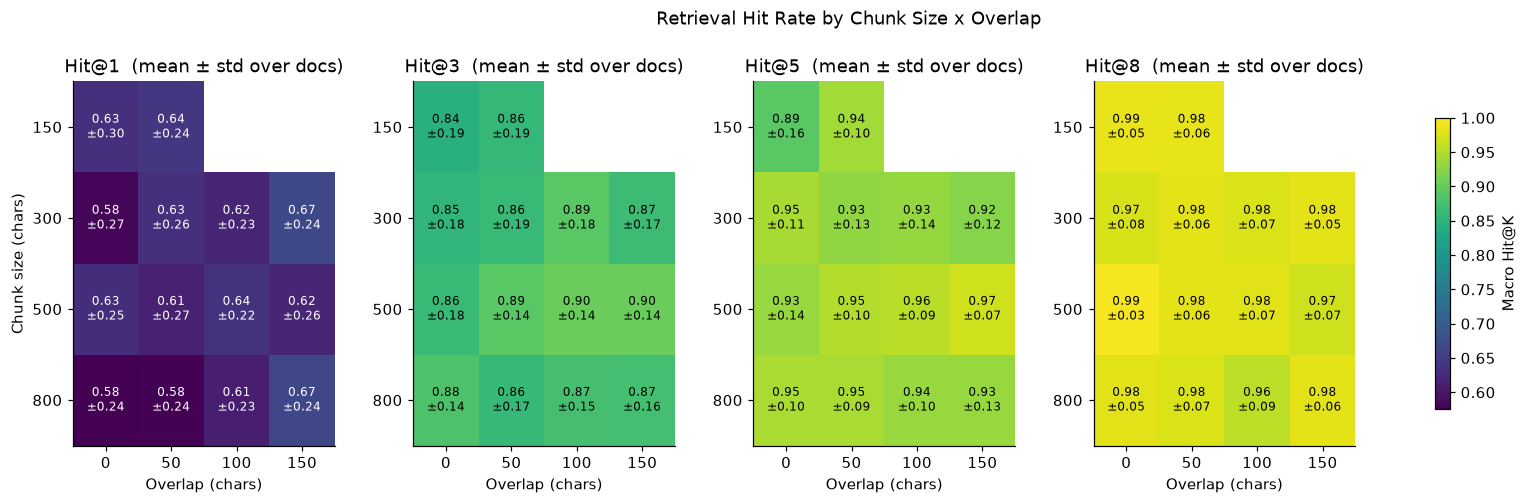

[saved] /cluster/home/m315832001/class/MMIP/week10/Outputs/Q1_grid_hit_heatmaps.png


In [9]:
Q1.plot_grid_heatmaps(summary, ks=(1, 3, 5, 8));

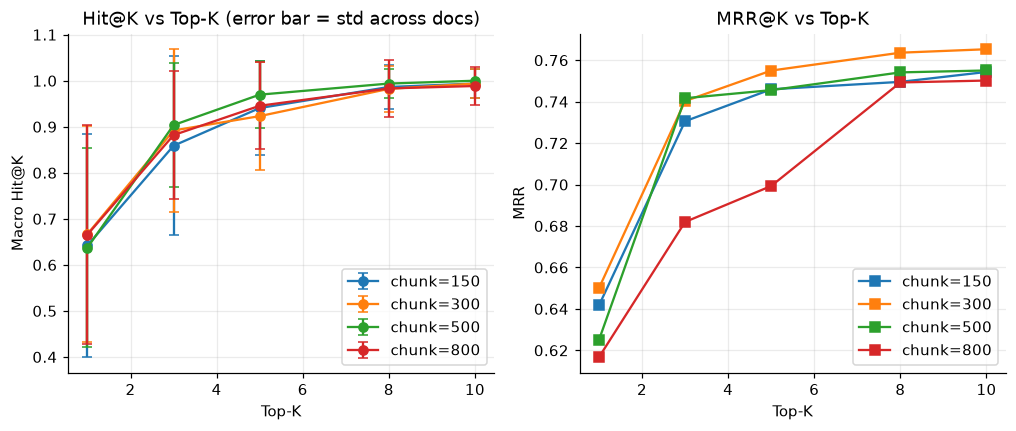

[saved] /cluster/home/m315832001/class/MMIP/week10/Outputs/Q1_grid_hit_vs_topk.png


In [10]:
Q1.plot_k_curves(summary);

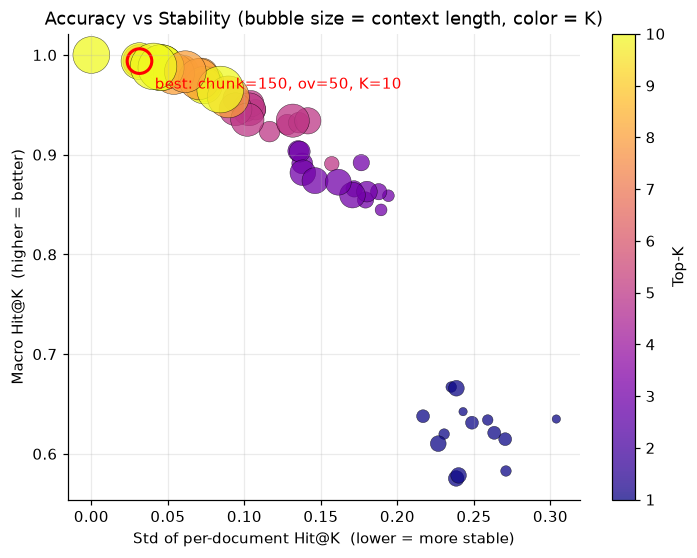

[saved] /cluster/home/m315832001/class/MMIP/week10/Outputs/Q1_grid_stability_scatter.png


In [11]:
Q1.plot_stability_scatter(summary);

**觀察**

* 熱力圖：K = 1 時各格都在 0.58–0.67，差異小；K 增加後全部上升，K = 8 時都在 0.96–0.99。
* Top-K 曲線：Hit 從 K = 1 → 3 躍升最多（約 0.6 → 0.85–0.90），K ≥ 5 後趨於平坦，代表 K 再加大主要是增加 context 成本。
* 穩定性散佈圖：K 越大的點（黃色）越靠左上（高命中、低標準差）；**K = 1 的點（深藍）標準差 0.22–0.30**，表示只取 1 個 chunk 時，
  命中率會因文件主題而有很大差異，最不穩定。紅圈是依 score 選出的第一名 `150 / 50 / K = 10`。

**第二階段**：取 score 最高的 3 組設定，做端到端（答案品質）驗證，選出最終設定。

candidates: [{'chunk_size': 150, 'overlap': 50, 'k': 10}, {'chunk_size': 150, 'overlap': 0, 'k': 8}, {'chunk_size': 150, 'overlap': 50, 'k': 8}]


,judge,char_f1,hit
config,,,
c150/o0/k8,4.583,0.587,0.983
c150/o50/k10,4.533,0.569,0.983
c150/o50/k8,4.700,0.566,0.983


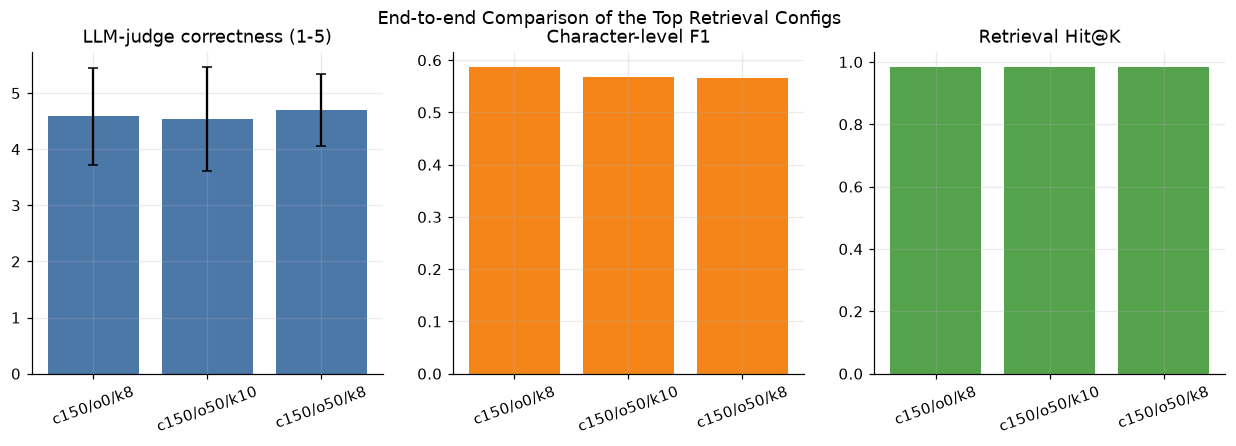

[saved] /cluster/home/m315832001/class/MMIP/week10/Outputs/Q1_end2end_top_configs.png


In [12]:
cands = Q1.top_configs(summary, n=3)
print("candidates:", cands)
rng = np.random.default_rng(0)
qa_eval = [qa[i] for i in rng.choice(len(qa), size=min(60, len(qa)), replace=False)]
e2e = Q1.evaluate_end2end(llm, embedder, corpus, qa_eval, cands)
display(e2e.groupby("config")[["judge", "char_f1", "hit"]].mean().round(3))
Q1.plot_end2end(e2e);

In [13]:
g = e2e.groupby("config")[["judge", "hit"]].mean()
best_name = (g["judge"] / 5 + g["hit"]).idxmax()
best_cfg = next(c for c in cands if f"c{c['chunk_size']}/o{c['overlap']}/k{c['k']}" == best_name)
print("BEST:", best_cfg)

final_chunks = Q1.build_chunks(corpus, best_cfg["chunk_size"], best_cfg["overlap"])
print("final #embeddings:", len(final_chunks), "(>=200 ✔)" if len(final_chunks) >= 200 else "(<200 ✘ → 改用預設 300/50)")
index = Q1.VectorIndex.build(final_chunks if len(final_chunks) >= 200 else chunks, embedder)
index.save("q1_index")
Q1.save_best_config(best_cfg)

BEST: {'chunk_size': 150, 'overlap': 50, 'k': 8}
final #embeddings: 1363 (>=200 ✔)


[saved] /cluster/home/m315832001/class/MMIP/week10/Outputs/q1_index.npz + q1_index_chunks.json
[saved] q1_best_config.json {'chunk_size': 150, 'overlap': 50, 'k': 8, 'technique': 'grounded_strict'}


**觀察**

* 端到端驗證（60 題，Qwen2.5-7B 回答 + LLM-judge）三組候選：`150/50/K8`（judge **4.700**、Hit 0.983）、`150/0/K8`（4.583、0.983）、
  `150/50/K10`（4.533、0.983）。三者 Hit 相同，judge 差距約 0.17 分（n = 60），**差異不顯著**；
  依 judge 選出最終設定 **chunk 150 / overlap 50 / Top-K 8**。
* 最終索引 **1,363 個 chunk**（≥ 200 ✔），已存成 `Outputs/q1_index.npz` 與 `q1_best_config.json`。
* char_f1 約 0.57：LLM 會改寫措辭，字元重疊低不代表答錯，judge 分數較能反映正確度。

## Q1.7 進階 ②：最合適的 Prompting Technique
比較 5 種：`zero_shot` / `grounded_strict`（嚴格規則+引用）/ `few_shot` / `cot`（`<think>` 先分析）/ `extract_then_answer`（先摘錄再回答）。
指標：LLM-judge 正確度、字元 F1、引用率、**無法回答題的正確拒答率**（12 題語料外問題，用來量測幻覺）、長度與延遲。

In [14]:
pr = Q1.evaluate_prompting(llm, index, qa_eval, k=best_cfg["k"])
pr.to_csv(OUT_DIR / "q1_prompting_results.csv", index=False)
display(pr.groupby(["technique", "kind"])[["judge", "char_f1", "cited", "refused", "length", "sec_per_q"]].mean().round(3))

[prompting] zero_shot done
[prompting] grounded_strict done
[prompting] few_shot done
[prompting] cot done
[prompting] extract_then_answer done


judge  char_f1  cited  refused   length  \
technique           kind                                                    
cot                 answerable    4.367    0.461  0.983    0.017   69.983   
                    unanswerable    NaN      NaN  0.000    1.000   10.000   
extract_then_answer answerable    3.933    0.515  0.983    0.000   54.383   
                    unanswerable    NaN      NaN  0.000    1.000   10.000   
few_shot            answerable    4.750    0.428  0.883    0.000  132.083   
                    unanswerable    NaN      NaN  0.000    1.000   13.500   
grounded_strict     answerable    4.700    0.566  1.000    0.033   70.400   
                    unanswerable    NaN      NaN  0.000    1.000   10.000   
zero_shot           answerable    4.583    0.333  0.317    0.000  207.117   
                    unanswerable    NaN      NaN  0.000    0.417  120.333   

                                  sec_per_q  
technique           kind                     
cot                 answerable        1.454  
                    unanswerable      1.454  
extract_then_answer answerable        1.013  
                    unanswerable      1.013  
few_shot            answerable        0.989  
                    unanswerable      0.989  
grounded_strict     answerable        0.667  
                    unanswerable      0.667  
zero_shot           answerable        1.344  
                    unanswerable      1.344

**觀察**

| 技術 | judge(1–5) | 字元 F1 | 引用率 | 語料外題「正確拒答」 | 可回答題誤拒答 | 平均長度 | 秒/題 |
|---|---|---|---|---|---|---|---|
| **grounded_strict** | 4.700 | **0.566** | **1.000** | **100%** | 3.3% | 70 字 | **0.67** |
| few_shot | **4.750** | 0.428 | 0.883 | **100%** | 0% | 132 字 | 0.99 |
| zero_shot | 4.583 | 0.333 | 0.317 | **42%** | 0% | 207 字 | 1.34 |
| cot | 4.367 | 0.461 | 0.983 | **100%** | 1.7% | 70 字 | 1.45 |
| extract_then_answer | 3.933 | 0.515 | 0.983 | **100%** | 0% | 54 字 | 1.01 |

* **zero_shot 不適合 RAG**：正確度看似不差（4.58），但 12 題語料外問題只有 42% 會拒答 → **58% 的幻覺率**，而且只有 32% 的答案有引用。
* **選擇 grounded_strict**（嚴格規則 + 強制引用 + 資料不足就拒答）：judge 只比 few_shot 低 0.05（不顯著），
  但字元 F1 最高、**每個答案都有引用**、語料外題全部拒答、而且最快、答案長度只有 few_shot 的一半。
* few_shot 正確度最高但答案冗長（132 字）、12% 沒有引用；`extract_then_answer` 最差（judge 3.9），先摘錄再作答容易漏掉細節。
* 副作用：grounded_strict 對可回答的題目有 2 / 60 題誤拒答（3.3%），是「嚴格」的代價。

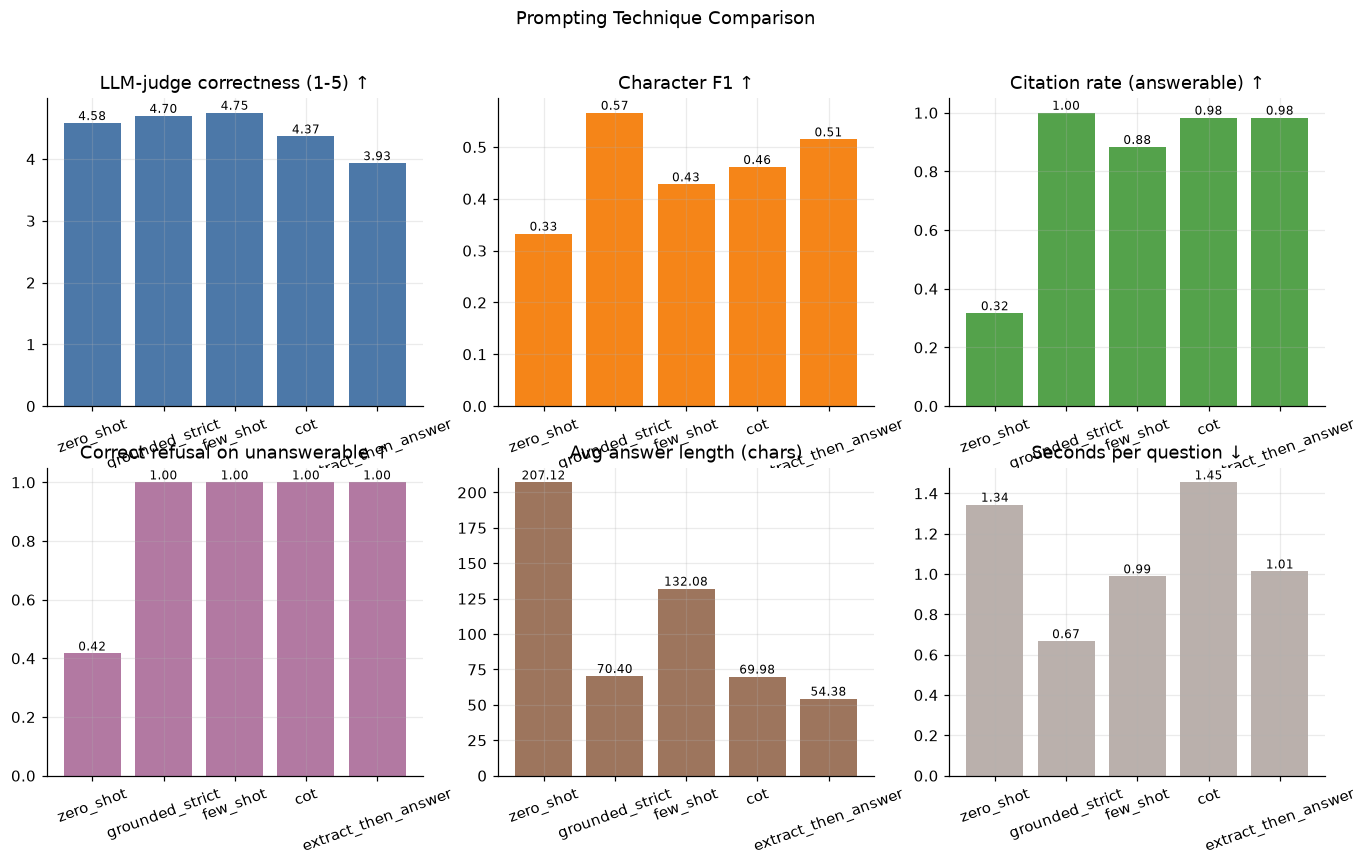

[saved] /cluster/home/m315832001/class/MMIP/week10/Outputs/Q1_prompting_technique_comparison.png


In [15]:
Q1.plot_prompting(pr);

In [16]:
best_tech = Q1.choose_technique(pr)
print("BEST prompting technique:", best_tech)
Q1.save_best_config(best_cfg, best_tech)

BEST prompting technique: grounded_strict
[saved] q1_best_config.json {'chunk_size': 150, 'overlap': 50, 'k': 8, 'technique': 'grounded_strict'}


## Q1.8 進階 ③：User Interface（Gradio）
左：對話；右：Top-K / Prompt 技術 / 查詢改寫開關、**改寫後的獨立查詢**、**可展開的 Reference（標示被引用者）**。

In [17]:
chat = Q1.RAGChat(llm, index, top_k=best_cfg["k"], technique=best_tech, rewrite=True)
ui1 = Q1.launch_ui(chat, port=7860, share=True)        # 瀏覽器開 http://127.0.0.1:7860

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://e9af903a6f63d7571d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


**觀察**

* UI 已啟動（本機 `127.0.0.1:7860`），使用最終設定（chunk 150 / overlap 50 / Top-K 8、grounded_strict）。這次使用了 `share=True`，
  會產生 **公開的 gradio.live 連結（最多 1 週）**，任何人拿到連結都能使用你的 GPU；進入 Quiz 2 時 `release()` 會自動關閉 UI。

In [18]:
# ui1.close()   # 看完 UI 後執行，釋放 port（進入 Quiz 2 時 release() 也會自動關閉）

# Quiz 2 — 多輪對話 VideoRAG
### 錄影建議
把影片放到 `Data/q2_videos/voice/`（有說話）與 `Data/q2_videos/no_voice/`（無說話）（mp4/mov/mkv/webm）；**資料夾名稱即為有無說話的標籤**，ASR 偵測結果只作為對照：
* **有說話**的影片 4~6 支：邊操作/展示邊講解，30~120 秒
* **沒說話**的操作影片 4~6 支：螢幕錄影（安裝工具、操作網站、料理…），30~120 秒；主題彼此不同。

### 演算法（參考 VideoRAG, Jeong et al. 2025 並改編）
| | 原 VideoRAG | 本作業的改編 |
|---|---|---|
| 檢索單位 | 整支影片 | **10 秒 clip**（可回報時間戳） |
| 有聲影片 | ASR 字幕 | faster-whisper large-v3 逐字稿 |
| 無聲影片 | 以 VLM 產生輔助文字 | Qwen2.5-VL 對 4 張畫面產生**操作 / OCR 描述** |
| 檢索訊號 | 視覺 + 文字 | bge-m3(描述+逐字稿) ⊕ Chinese-CLIP(畫面)，**z-score 加權融合 α** |
| 生成 | LVLM(影片+字幕) | Qwen2.5-VL(畫面 + 描述 + 逐字稿)，帶 `[V#]` 引用 |
| 多輪 | — | **對話歷史查詢改寫**後再檢索 |

## Q2.1 前處理：影片盤點與切 clip

In [19]:
release(globals(), "ui1", "chat", "llm")   # 關閉 UI 並釋放 text LLM，才有空間載入 VLM
gpu_report(" after freeing text LLM")

videos = Q2.list_videos()
meta = Q2.probe_videos(videos)
display(meta[["vid_idx", "video_id", "duration", "fps", "width", "height"]].round(1))
clips = Q2.make_clips(meta)
Q2.extract_all_frames(clips)
print(f"{len(videos)} videos -> {len(clips)} clips ({Q2.CLIP_LEN:.0f}s each, {Q2.FRAMES_PER_CLIP} frames per clip)")

Closing server running on port: 7860
[unload] ChatLLM (Qwen/Qwen2.5-7B-Instruct)
[GPU] after release torch-allocated 1.1 GB | device used 1.5 / 23.6 GB
[GPU] after freeing text LLM torch-allocated 1.1 GB | device used 1.5 / 23.6 GB


,vid_idx,video_id,duration,fps,width,height
0,0,"Change the format of the excel table, if the cell contains specific piece of text, lesson 47",25.2,30.0,1920,1080
1,1,"Create new file in Excel from templates, lesson 2",20.2,30.0,1280,720
2,2,"How to Scan Documents to PDF in Google Drive (Free & Easy Method) - Pro Support (1080p, h264)",128.0,30.0,1280,720
3,3,"How to Upload Designs to TeePublic & Make Extra Money - HotmessexpressCEO (720p, h264).mp4",82.7,30.0,1280,720
4,4,"Turbo VPN App Download & Install How to Use Turbo VPN on Android - Pro Support (720p, h264)",82.1,30.0,1920,1080
5,5,Excel AVERAGE Function _ How to use AVERAGE function _ Excel One Minute Quick Reference_720p,101.3,30.0,1280,720
6,6,Excel MAX Function _ Find the maximum of a range of numbers _ Excel One Minute Quick Reference_720p,69.2,30.0,1280,720
7,7,Explain RAG in 1 minute_720p,79.1,30.0,720,720
8,8,How to Record Your iPhone Screen in Under 60 Seconds #Shorts,42.1,30.0,608,1080
9,9,OneNote For Mac How to Record Audio 1 Minute Tutorial,49.3,30.0,1920,1080


10 videos -> 68 clips (10s each, 4 frames per clip)


**觀察**

* **10 支影片 → 68 個 10 秒 clip**，時長 20–128 秒；前 5 支（`vid0–4`）為 `no_voice` 操作影片，後 5 支（`vid5–9`）為 `voice` 講解影片。

## Q2.2 前處理：ASR — 區分「有說話」/「無說話」影片
ASR 在子行程執行（用完即釋放顯存）。後端依序嘗試：faster-whisper large-v3（GPU）→ transformers `whisper-large-v3-turbo`（GPU）→ faster-whisper（CPU）。
本環境缺 CUDA 12 函式庫，所以實際使用 **transformers whisper-large-v3-turbo**；逐字稿用 word-level 時間戳重新組成 ≤ 8 秒的句子，才能對應到 10 秒的 clip。

,video_id,speech_ratio,chars,asr_has_speech,folder_label,has_speech
0,"Change the format of the excel table, if the cell contains specific piece of text, lesson 47",1.00,9,False,no_voice,False
1,"Create new file in Excel from templates, lesson 2",1.00,9,False,no_voice,False
2,"How to Scan Documents to PDF in Google Drive (Free & Easy Method) - Pro Support (1080p, h264)",0.77,18,True,no_voice,False
3,"How to Upload Designs to TeePublic & Make Extra Money - HotmessexpressCEO (720p, h264).mp4",0.88,18,True,no_voice,False
4,"Turbo VPN App Download & Install How to Use Turbo VPN on Android - Pro Support (720p, h264)",0.88,18,True,no_voice,False
5,Excel AVERAGE Function _ How to use AVERAGE function _ Excel One Minute Quick Reference_720p,0.71,984,True,voice,True
6,Excel MAX Function _ Find the maximum of a range of numbers _ Excel One Minute Quick Reference_720p,0.60,541,True,voice,True
7,Explain RAG in 1 minute_720p,0.90,1295,True,voice,True
8,How to Record Your iPhone Screen in Under 60 Seconds #Shorts,0.75,604,True,voice,True
9,OneNote For Mac How to Record Audio 1 Minute Tutorial,0.80,690,True,voice,True


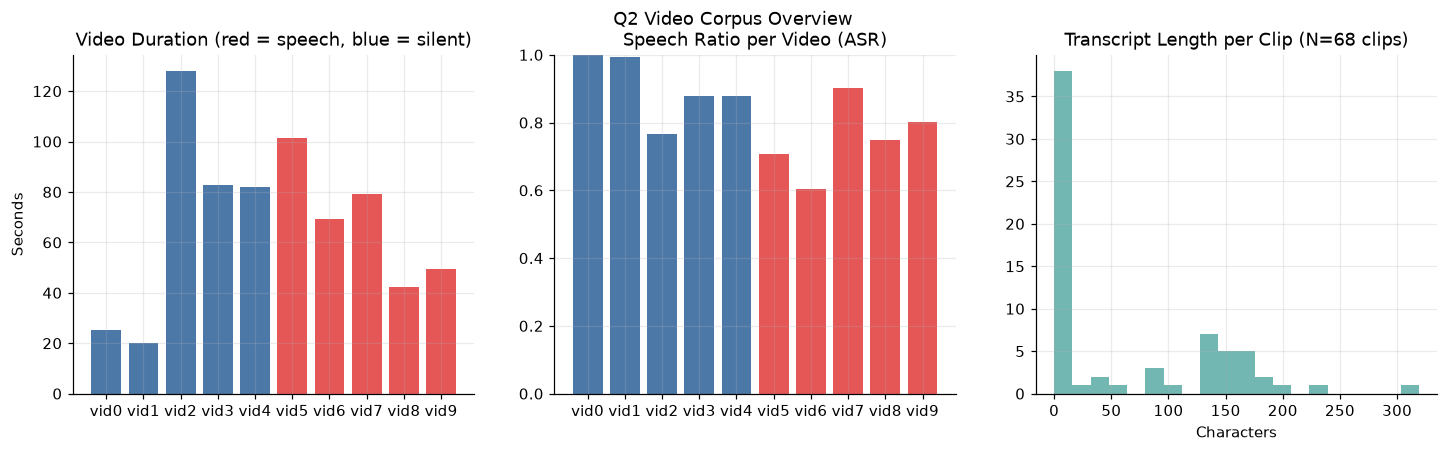

[saved] /cluster/home/m315832001/class/MMIP/week10/Outputs/Q2_video_corpus_overview.png


In [20]:
asr = Q2.transcribe_videos(videos)               # faster-whisper large-v3 (用完自動釋放)
vdf = Q2.attach_transcripts(clips, asr, meta)
display(vdf.round(2))
Q2.plot_corpus_overview(meta, vdf, clips);

**觀察**

* ✅ **ASR 成功**：5 支 `voice` 影片都有完整逐字稿（541–1,295 字，語音佔影片長度 60–90%），例如 Excel MAX 影片
  「I'm going to use AutoSum on the Home tab… The max is now 50.」
* `no_voice` 影片也被 Whisper 「聽出」 9–18 個字（典型的幻覺，如 `Thank you.`），ASR 判斷甚至把其中 3 支標成有語音（`asr_has_speech = True`）。
  這說明**單靠 ASR 判斷有無說話並不可靠**，所以以資料夾標籤為準（`has_speech`），`no_voice` 影片的逐字稿一律丟棄，避免幻覺文字進入索引。

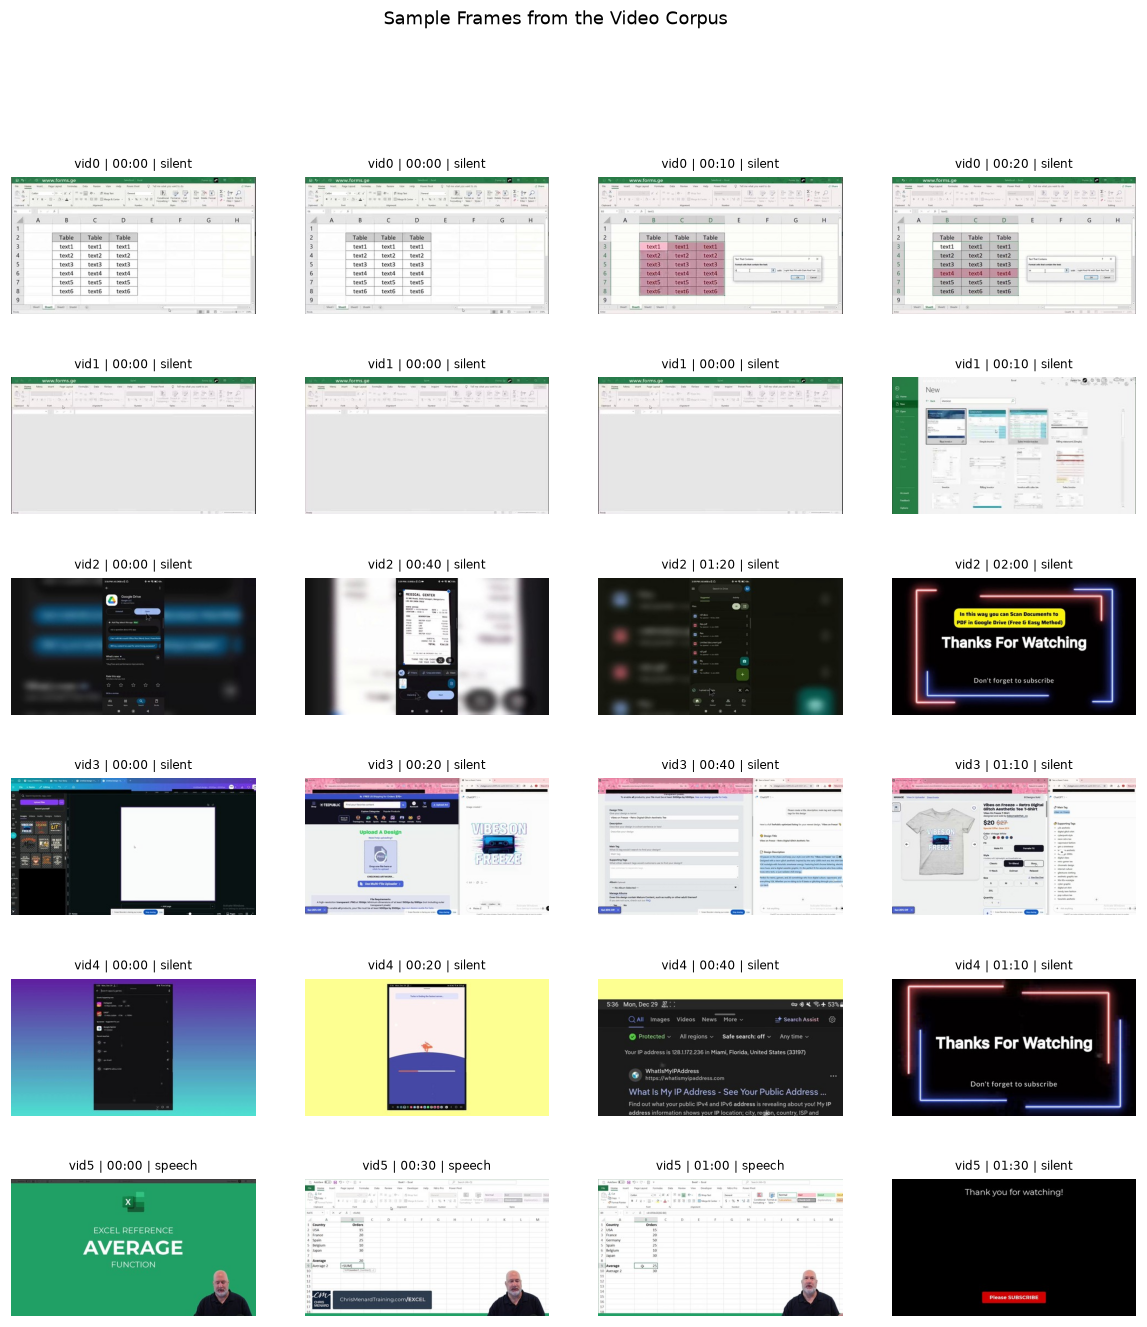

[saved] /cluster/home/m315832001/class/MMIP/week10/Outputs/Q2_frame_samples.png


In [21]:
Q2.plot_frame_samples(clips);

## Q2.3 前處理：以 VLM 為每個 clip 產生輔助文字（畫面描述 / 操作 / OCR）

In [22]:
release(globals(), "ui1", "chat", "llm", "vlm")   # 保險：載入 VLM 前再確認 text LLM 已卸載（約需 16 GB 空位）
vlm = VLM()                                      # Qwen2.5-VL-7B-Instruct
gpu_report(" after VLM")
Q2.caption_clips(vlm, clips)
for c in clips[:3]:
    print(f"[{c['video_id']} {fmt_time(c['start'])}] caption: {c['caption']}\n   transcript: {c['transcript'] or '(none)'}\n")

[GPU] after release torch-allocated 1.1 GB | device used 1.4 / 23.6 GB


Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

[GPU] after VLM torch-allocated 16.5 GB | device used 16.9 / 23.6 GB
[Change the format of the excel table, if the cell contains specific piece of text, lesson 47 00:00] caption: (1) 圖片顯示的是Excel表格界面，背景是白色。(2) 操作者使用鼠标点击了表格中的单元格。(3) 画面上可见的文字有“Change the format of the excel table, if the cell contains specific piece of text, lesson 47”。
   transcript: (none)

[Change the format of the excel table, if the cell contains specific piece of text, lesson 47 00:10] caption: (1) 圖片顯示一個 Excel 工作表，其中包含三個表格和一些文字。 (2) 使用者點擊「Text That Contains」選項，並在對話框中輸入「text1」。 (3) 「Text That Contains」、「Format cells that contain the text」、「OK」、「Cancel」等字樣。
   transcript: (none)

[Change the format of the excel table, if the cell contains specific piece of text, lesson 47 00:20] caption: (1) 圖片顯示一個Excel工作表，其中包含多個表格和文字。 (2) 使用者在Excel中使用「Text That Contains」功能，並輸入了「1」作為搜索條件。 (3) 「Text That Contains」對話框中顯示了搜索條件「1」，以及選項「with Light Red Fill with Dark Red Text」。
   transcript: (none)



**觀察**

* VLM 載入後顯存 16.5 GB。caption 能抓到畫面上的 OCR 文字與操作（例如「Text That Contains」對話框、「with Light Red Fill…」選項），
  所以即使沒有旁白，操作影片仍然有可檢索的文字。
* 觀察：caption 混用簡繁體（模型回應有時是簡體），且第 1 個 clip 只描述了標題文字，資訊量較低。

## Q2.4 建立雙索引（文字 bge-m3 ⊕ 視覺 Chinese-CLIP）

Loading weights:   0%|          | 0/591 [00:00<?, ?it/s]

[saved] /cluster/home/m315832001/class/MMIP/week10/Outputs/q2_videorag_index.npz + q2_videorag_index_clips.json
text_emb (68, 1024) | vis_emb (68, 768)
[GPU] all models loaded torch-allocated 17.3 GB | device used 17.8 / 23.6 GB


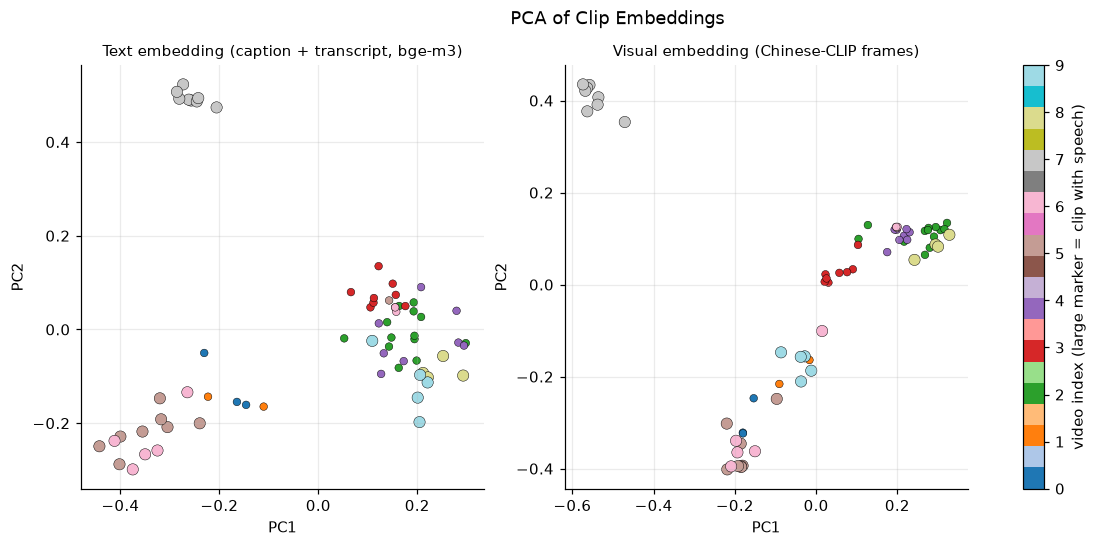

[saved] /cluster/home/m315832001/class/MMIP/week10/Outputs/Q2_clip_embedding_space.png


In [23]:
if "embedder" not in globals():          # kernel 重啟後從這裡開始時也能跑
    embedder = Embedder()
clip_model = Q2.ChineseCLIP()
vindex = Q2.VideoRAGIndex.build(clips, embedder, clip_model)
vindex.save("q2_videorag_index")
print("text_emb", vindex.text_emb.shape, "| vis_emb", vindex.vis_emb.shape)
gpu_report(" all models loaded")
Q2.plot_index_space(vindex);

**觀察**

* 文字向量 `(68, 1024)`（caption + 逐字稿）、視覺向量 `(68, 768)`（4 張畫面平均），已存成 `Outputs/q2_videorag_index.npz`。
* 顯存：三個模型同時載入 17.3 GB，還有約 6 GB 的空間給推論時的圖片 token。

## Q2.5 展示：多輪 VideoRAG 對話（請依你的影片內容修改 `Q2.DEMO_TURNS`）

In [24]:
vchat = Q2.VideoRAGChat(vlm, vindex, top_k=3, mode="fusion", alpha=0.6)
vdemo = Q2.run_demo_conversation(vchat)         # 例：自行改成  turns=["…", "它…", "那…"]


===== Turn 1 =====
👤 有沒有影片是在教怎麼在 Excel 裡計算平均值或最大值？
🤖 是的，影片中有教怎麼在 Excel 裡計算平均值或最大值。[V1] 和 [V2] 分別介紹了如何使用 Excel 中的 AVERAGE 函數和 MAX 函數。[V1] 在 00:00–00:10 時間段介紹了 AVERAGE 函數，[V2] 在 00:00–00:10 時間段介紹了 MAX 函數。
📎 References:
   [V1] ✔ cited | vid5 Excel AVERAGE Function _ How to use AVERAGE function _ Excel One Minute Quick Reference_720p 00:00-00:10 | fused=2.37 (text z=2.35, visual z=2.40)
   [V2] ✔ cited | vid6 Excel MAX Function _ Find the maximum of a range of numbers _ Excel One Minute Quick Reference_720p 00:00-00:10 | fused=2.29 (text z=2.27, visual z=2.31)
   [V3]   retrieved | vid5 Excel AVERAGE Function _ How to use AVERAGE function _ Excel One Minute Quick Reference_720p 00:40-00:50 | fused=1.92 (text z=2.11, visual z=1.65)

===== Turn 2 =====
👤 那個函數要怎麼輸入？
🔁 standalone query: Excel 中的 AVERAGE 函數和 MAX 函數要怎麼輸入？
🤖 [AVERAGE 函數] 要輸入 AVERAGE 函數，首先選擇要計算平均值的範圍，例如 B2:B6。然後在公式編輯器中輸入 =AVERAGE(B2:B6)，最後按 Enter 鍵即可得到結果。[V1] 00:10–00:20

[Max 函數] 要輸入 MAX 函數，選擇要查找最大值的範圍，例如 C2:C6。然後在公式編輯器中輸入 =MAX

**觀察**

* **Turn 1**：問 Excel 平均值 / 最大值，前兩名正是 AVERAGE 與 MAX 兩支影片的開頭 clip（融合分數 2.37 / 2.29，文字與視覺 z 分數都高），兩者都被引用。
* **Turn 2**：「那個函數要怎麼輸入？」被改寫為「Excel 中的 AVERAGE 函數和 MAX 函數要怎麼輸入？」，成功還原代名詞，
  並分別說明 `=AVERAGE(B2:B6)`、`=MAX(C2:C6)` 的輸入方式。
  ⚠️ 答案標註 `[V1] 00:10–00:20`，但 V1 實際是 `00:00–00:10`，**時間戳是模型自己編的**，這是 Q3-B 要另外評估引用正確率的原因。
* **Turn 3**：換話題問 RAG，前 3 名都是 `Explain RAG in 1 minute`（融合分數 2.55–2.72 最高），答案合理。
* **Turn 4**：問「示範螢幕錄影的影片、第一步？」，**這次答對**：iPhone 錄影影片（vid8）排第 1，回答「第一步是進入設定並選擇控制中心」。
  它的文字 z 分數 2.50 遠高於視覺 1.28 —— 有了 ASR 逐字稿後，有聲影片的內容才能被文字檢索找到（ASR 失敗時這一輪會誤答「找不到」）。

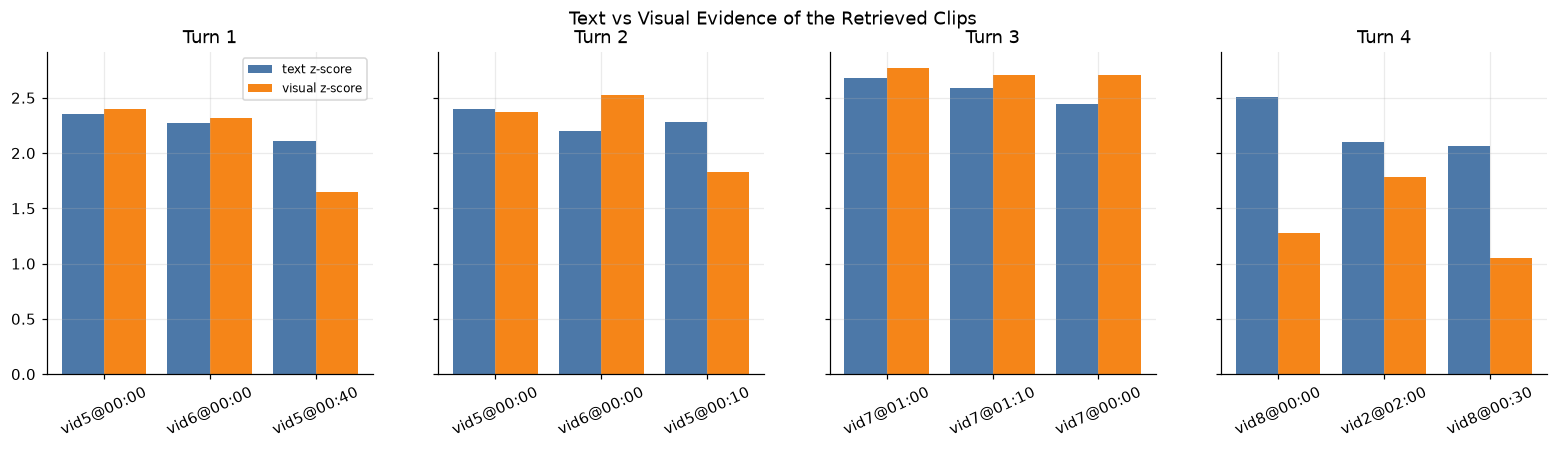

[saved] /cluster/home/m315832001/class/MMIP/week10/Outputs/Q2_demo_fusion_scores.png


In [25]:
Q2.plot_fusion_scores(vdemo);

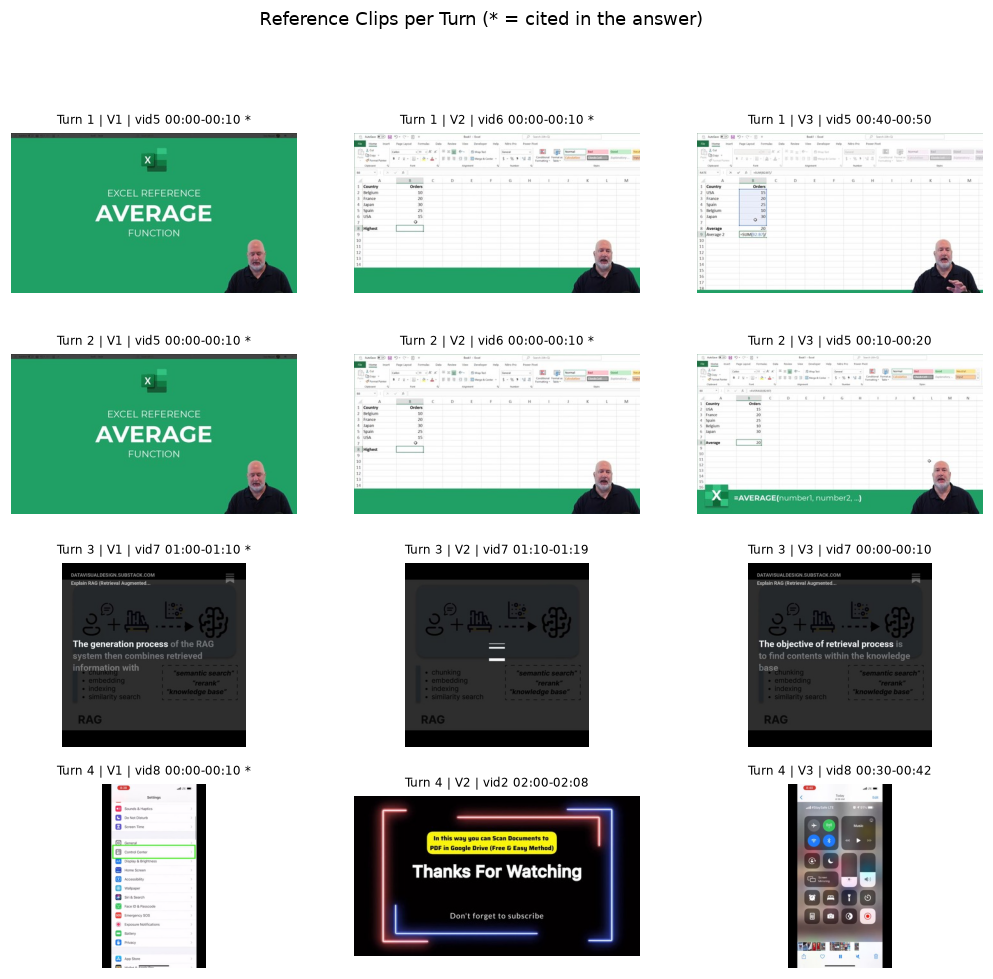

[saved] /cluster/home/m315832001/class/MMIP/week10/Outputs/Q2_multiturn_reference_frames.png


In [26]:
Q2.plot_reference_sheet(vdemo);

## Q2.6 UI：聊天 + 參考片段（自動剪出被引用的 clip 播放）+ 參考畫面 + 融合分數
需要系統有 `ffmpeg` 才會剪片段；沒有的話只顯示畫面圖庫。

In [27]:
# 看完後務必 ui2.close()，否則 vchat -> VLM 會一直佔著顯存
ui2 = Q2.launch_ui(vchat, port=7861)       # http://127.0.0.1:7861

* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.


**觀察**

* Video UI 已在 `127.0.0.1:7861` 啟動並關閉（`ui2.close()`），未開公開連結。

In [28]:
ui2.close()

Closing server running on port: 7861


# Quiz 3 — 評估 RAG 系統
**A. 文字 RAG（Quiz 1）**：RAGAS 的四個核心指標 *faithfulness / answer relevancy / context precision / context recall*，
外加 answer correctness 與以黃金證據計算的 Hit / MRR / nDCG。
> 官方 `ragas` 套件預設呼叫 OpenAI；為了完全本地執行，這裡**依 RAGAS 定義用 Qwen2.5-7B 作為 judge 重新實作**（見 `Quiz3.ragas_style_eval`）。

**B. VideoRAG**：延伸 RAGAS 的想法 → 依問題模態分層（speech / visual）、時間容忍的 clip 命中、模態消融與 α 掃描、
以**原始畫面+逐字稿**作證據的視覺 faithfulness、引用正確率、多輪改寫消融。

## Q3.A.1 準備：載入文字 LLM 與 Quiz1 最佳設定

In [29]:
release(globals(), "ui2", "vchat", "vlm", "clip_model", "vindex")   # 先關掉 UI 才釋放得掉 VLM
if "embedder" not in globals():
    embedder = Embedder()
llm = ChatLLM()
cfg = Q1.load_best_config(); print("Quiz1 best config:", cfg)
index = Q1.VectorIndex.load(embedder)
qa = json.load(open(DATA_DIR / "q1_qa_dataset.json", encoding="utf-8"))
mt = json.load(open(DATA_DIR / "q1_multiturn_dataset.json", encoding="utf-8"))
rng = np.random.default_rng(1)
qa_eval = [qa[i] for i in rng.choice(len(qa), size=min(60, len(qa)), replace=False)]
recs = Q3.build_rag_records(llm, index, qa_eval, k=cfg["k"], technique=cfg["technique"])
print(len(recs), "records")

[unload] VLM (Qwen/Qwen2.5-VL-7B-Instruct)
[unload] ChineseCLIP ()
[GPU] after release torch-allocated 1.1 GB | device used 1.4 / 23.6 GB


Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

Quiz1 best config: {'chunk_size': 150, 'overlap': 50, 'k': 8, 'technique': 'grounded_strict'}
60 records


## Q3.A.2 RAGAS-style 評估

In [30]:
ragas_df = Q3.ragas_style_eval(llm, embedder, recs)
ragas_df.to_csv(OUT_DIR / "q3_ragas_results.csv", index=False)
display(ragas_df[Q3.RAGAS_COLS + ["char_f1", "sem_sim"]].agg(["mean", "std"]).round(3))

,hit,mrr,ctx_precision,ctx_recall,faithfulness,answer_relevancy,answer_correctness,char_f1,sem_sim
mean,1.0,0.726,0.803,0.828,0.858,0.763,0.903,0.564,0.796
std,0.0,0.346,0.175,0.269,0.191,0.197,0.163,0.274,0.154


**觀察**

| 指標 | 平均 | 標準差 | 意義 |
|---|---|---|---|
| Hit（黃金證據是否在 Top-8） | **1.000** | 0 | 60 題全部檢索到證據 |
| MRR | 0.726 | 0.346 | 證據平均排在第 1–2 名，但有不少題排在第 3 名以後 |
| Context precision | 0.803 | 0.175 | 檢索到的 8 個 chunk 多數有用 |
| Context recall | 0.828 | 0.269 | 標準答案的陳述大多能從 context 推出 |
| Faithfulness | 0.858 | 0.191 | 約 14% 的答案陳述沒有被 context 支持 |
| **Answer relevancy** | **0.763** | 0.197 | **最弱的指標**：答案常附帶額外說明，不夠直接 |
| Answer correctness (judge/5) | 0.903 | 0.163 | 約 4.5 / 5 分 |
| 字元 F1 / 語意相似 | 0.564 / 0.796 | 0.274 / 0.154 | F1 偏低是因為答案比標準答案長，不等於錯 |

* 檢索端 Hit = 1，**瓶頸在生成端**：answer relevancy 與 context precision 最低，表示模型會補充 context 以外或與問題無關的說明。
* 與第一次執行（10 篇、未過濾的 QA）相比，faithfulness 從 0.76 提升到 0.86、MRR 從 0.83 降到 0.73：語料變大後檢索排序變難，
  但 QA 經過品質過濾，答案更貼近證據（兩者同時改變，無法完全分開歸因）。
* 注意 judge 是同一個 Qwen2.5-7B（自評偏誤可能讓分數偏高），報告中應如實註明。

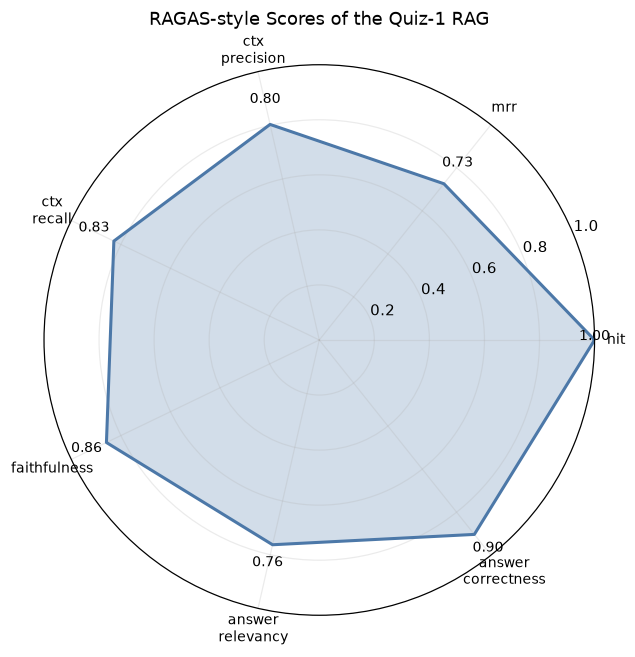

[saved] /cluster/home/m315832001/class/MMIP/week10/Outputs/Q3_ragas_radar.png


In [31]:
Q3.plot_ragas_radar(ragas_df);

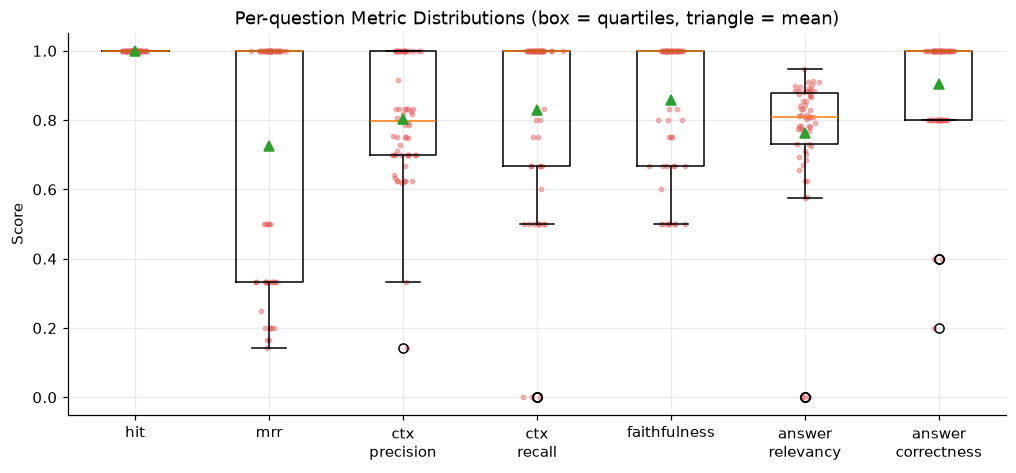

[saved] /cluster/home/m315832001/class/MMIP/week10/Outputs/Q3_ragas_metric_distributions.png


In [32]:
Q3.plot_metric_distributions(ragas_df);

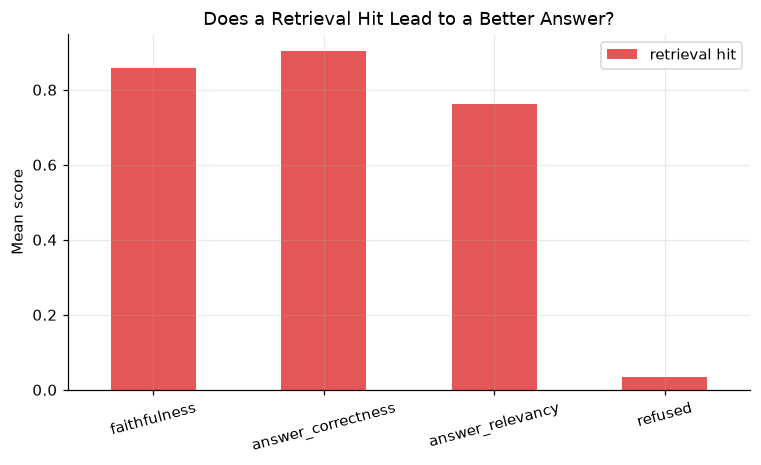

[saved] /cluster/home/m315832001/class/MMIP/week10/Outputs/Q3_hit_vs_generation.png


In [33]:
Q3.plot_retrieval_vs_generation(ragas_df);

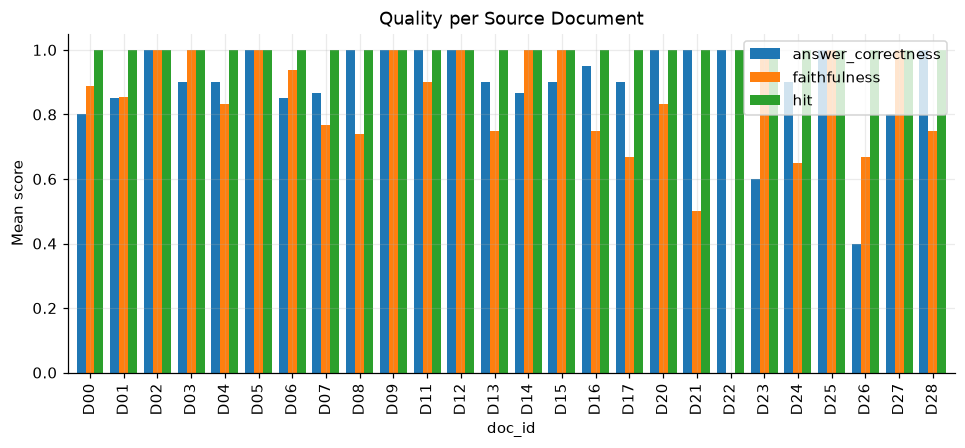

[saved] /cluster/home/m315832001/class/MMIP/week10/Outputs/Q3_correctness_by_document.png


In [34]:
Q3.plot_metrics_by_doc(ragas_df);

**觀察**

* 雷達圖：hit = 1.00 在最外圈，answer_correctness 0.90、faithfulness 0.86 次之；answer_relevancy 0.76 與 MRR 0.73 內縮最多。
* 箱形圖：**MRR 分佈最分散**（四分位距 0.33–1.0，有一群題目的證據排在第 3–7 名）；answer_correctness 大多是 1.0 或 0.8，只有 3 題 ≤ 0.4；
  ctx_recall 與 answer_relevancy 有少數題掉到 0（多為模型拒答「資料不足」的題目）。
* 「檢索命中 vs 生成」圖只剩「retrieval hit」一組（所有題都命中，沒有 miss 組可比較）。

### 錯誤分析：答案正確度最低的 8 題

In [35]:
display(ragas_df.sort_values('answer_correctness').head(8)[['question', 'gold', 'answer', 'hit', 'faithfulness', 'answer_correctness']])

,question,gold,answer,hit,faithfulness,answer_correctness
13,什麼情況會導致模型的偏差小而方差大？,過適時，模型的偏差小而方差大。,資料不足，無法回答。,1.0,NaN,0.2
15,如果新產品D與產品B相似度高，會奪取產品B多少市場份額？,20%,根據參考資料[3]，如果新產品D與產品B相似度高，則新產品D的CP值高而奪去產品B的部分市場，使得產品B剩餘10%的市場份額。[3],1.0,0.666667,0.4
19,人工智慧在哪些領域模仿人類的創造能力？,包括AI作曲、AI作詩、AI小說、AI繪畫、AI設計等。,人工智慧在創造力領域模仿人類的創造能力，包括系統產生的輸出能否被視為創意，以及系統能否識別和評估創造力。[7],1.0,1.000000,0.4
6,Last.fm 推薦系統如何工作？,Last.fm 透過觀察使用者日常收聽的樂隊或歌手，並與其它使用者的行為進行比對，建立一個「電臺」，以此推薦歌曲。,Last.fm 通過觀察使用者日常收聽的樂隊或歌手，並與其他使用者的行為進行比對，建立一個「電臺」，以此推薦歌曲。[1] 此外，Last.fm 會播放不在使用者曲庫中，但其他相似使用者經常會播放的其他音樂。[3],1.0,0.500000,0.8
20,卷積神經網路在哪種應用中被證明可以有效處理語意分析？,卷積神經網路已被證明可以有效地處理各種自然語言處理的問題，如語意分析、搜尋結果提取、句子建模、分類、預測、和其他傳統的NLP任務。,根據參考資料，卷積神經網路被證明可以在自然語言處理領域有效處理語意分析。[3][5],1.0,1.000000,0.8
21,自然語言處理中越來越重視哪一方面？,自然語言處理中越來越重視詞彙的作用，出現了強烈的「詞彙主義」的傾向。,自然語言處理中越來越重視詞彙的作用。[3] [8],1.0,0.666667,0.8
23,線性回歸中，β̂ 的計算公式是什麼？,"β̂=∑i=1n(xi−x¯)(yi−y¯)∑i=1n(xi−x¯)2=cov(X,Y)var(X)",β̂ 的計算公式為：\n\[ \hat{\beta} = \frac{n\sum_{i=1}^{n}x_iy_i - \sum_{i=1}^{n}x_i\sum_{i=1}^{n}y_i}{\sum_{i=1}^{n}x_i^2 -...,1.0,NaN,0.8
7,哪些軟體包含聚類演算法？,"Tanagra 包含聚類演算法，如 K-MEANS, SOM, Clustering Tree, HAC 等。",Tanagra 包含多種聚類算法，例如 K-MEANS、SOM、聚类树、HAC 等。[3]\nYALE 和 Weka 也提供了聚類功能。[1][4]\nCluster 軟體也包含了聚類算法。[6]\n\n[3][4][6],1.0,0.833333,0.8


**觀察**

這 8 題的 **檢索都命中（hit = 1）**，低分原因都在生成端：
* **誤拒答**：「什麼情況會導致模型的偏差小而方差大？」證據有被檢索到，模型卻回答「資料不足，無法回答」（grounded_strict 太嚴格的代價）。
* **沒有直接回答**：「新產品 D 會奪取產品 B 多少市場份額？」標準答案 20%，模型只說「產品 B 剩餘 10%」；
  「人工智慧在哪些領域模仿人類的創造能力？」模型講的是「如何評估創造力」，沒有列出 AI 作曲、作詩、繪畫等。
* **judge 偏嚴**：線性回歸 β̂ 的公式，模型給的是代數上等價的另一種寫法，仍被扣到 0.8；聚類軟體題多列了其他 chunk 提到的 YALE、Weka 也被扣分。
* 和第一次執行相比，**最低分的題目中已經沒有「第一句和第二句的它們指什麼」這類不獨立的題目**，QA 品質過濾有效。

## Q3.A.3 多輪評估：查詢改寫是否有用？
四種處理追問的方式：原始追問 / 歷史串接 / LLM 改寫 / 人工獨立問題（上界）。

by follow-up kind (pronoun = same-topic follow-up, switch = topic change):


hit    mrr  correctness
kind    variant                                              
pronoun history_concat              0.846  0.526        0.638
        llm_rewrite                 0.808  0.500        0.623
        no_rewrite (raw follow-up)  0.308  0.213        0.492
        oracle_standalone           0.769  0.526        0.669
switch  history_concat              0.250  0.047        0.633
        llm_rewrite                 1.000  0.720        0.950
        no_rewrite (raw follow-up)  1.000  0.750        0.967
        oracle_standalone           1.000  0.750        0.967

,hit,mrr,correctness
variant,,,
history_concat,0.658,0.375,0.637
llm_rewrite,0.868,0.570,0.726
no_rewrite (raw follow-up),0.526,0.382,0.642
oracle_standalone,0.842,0.596,0.763


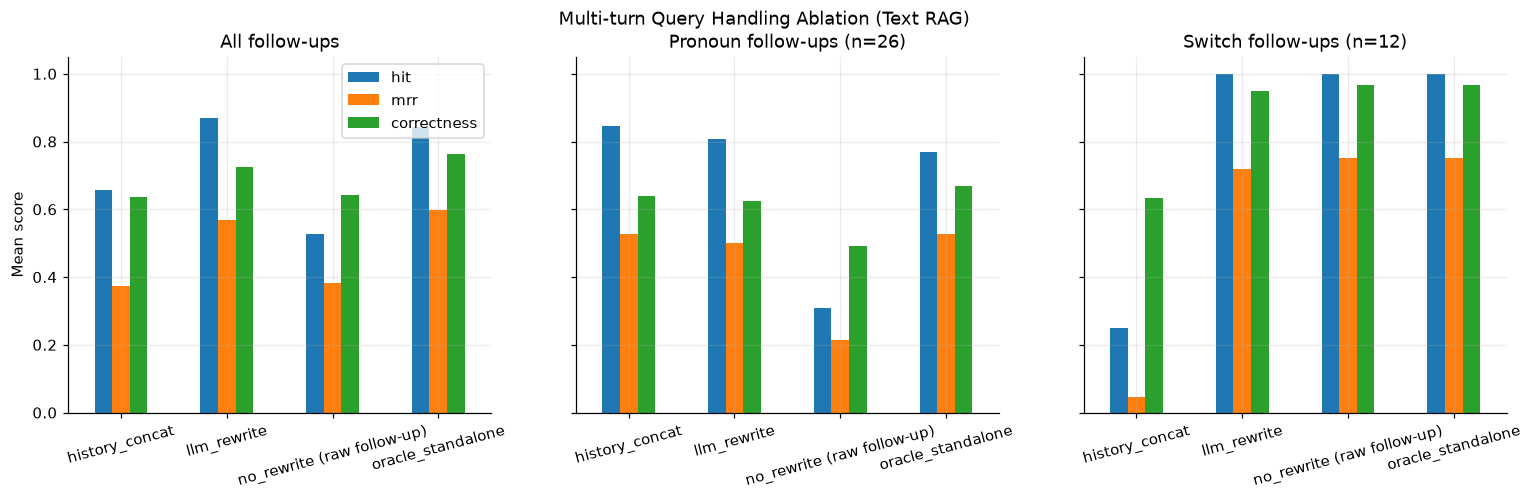

[saved] /cluster/home/m315832001/class/MMIP/week10/Outputs/Q3_multiturn_rewrite_ablation.png


In [36]:
mt_df = Q3.evaluate_multiturn_text(llm, index, mt, k=cfg["k"], technique=cfg["technique"])
mt_df.to_csv(OUT_DIR / "q3_text_multiturn.csv", index=False)
display(mt_df.groupby("variant")[["hit", "mrr", "correctness"]].mean().round(3))
Q3.plot_multiturn_ablation(mt_df);

**觀察**

| 處理追問的方式 | 代名詞追問 Hit / MRR / 正確度（26 題） | 換主題 Hit / MRR / 正確度（12 題） | 全部 Hit / MRR / 正確度（38 題） |
|---|---|---|---|
| no_rewrite（直接用追問） | 0.308 / 0.213 / 0.492 | **1.000 / 0.750 / 0.967** | 0.526 / 0.382 / 0.642 |
| history_concat（歷史串接） | **0.846 / 0.526** / 0.638 | **0.250 / 0.047** / 0.633 | 0.658 / 0.375 / 0.637 |
| **llm_rewrite（LLM 改寫）** | 0.808 / 0.500 / 0.623 | **1.000** / 0.720 / 0.950 | **0.868** / 0.570 / 0.726 |
| oracle_standalone（標準獨立問題） | 0.769 / 0.526 / **0.669** | 1.000 / 0.750 / 0.967 | 0.842 / **0.596** / **0.763** |

* **代名詞追問一定要處理**：直接用「那它的缺點呢？」檢索，Hit 只有 0.31；改寫或串接都能提升到 0.8 以上。
* **歷史串接只在同主題時有效**：同主題時最高（0.846），但**換主題時崩潰到 0.25**（MRR 0.05）——第一輪的內容把檢索拉回舊主題。
  第一次執行時串接看起來比改寫好，是因為資料集裡只有同主題追問。
* **LLM 改寫在兩種情況都穩定**：同主題 0.808、換主題 1.000，**整體 Hit 0.868 最高**，甚至略高於標準獨立問題（0.842，差 1 題，不顯著）；
  標準獨立問題（oracle）現在也明顯高於歷史串接（0.842 vs 0.658），符合它作為參考上界的角色。
* 答案正確度（judge/5）各方式差距較小（0.64–0.76，n = 38），而且多輪題的標準答案較開放，不宜過度解讀。

## Q3.B.1 VideoRAG Benchmark（silver label）
語音題由逐字稿出題（要求換句話說，降低字面洩漏）；視覺題由 VLM **直接看畫面**出題，不看索引用的 caption。
> 產生後請打開 `Data/q2_video_qa.json` 人工修正錯題，即成 gold benchmark。

In [37]:
release(globals(), "chat", "llm")
if "embedder" not in globals():
    embedder = Embedder()
vlm = VLM(); clip_model = Q2.ChineseCLIP()
vindex = Q2.VideoRAGIndex.load(embedder, clip_model)
vqa = Q3.build_video_benchmark(vlm, vindex.clips, n_speech=20, n_visual=20)
vmt = Q3.build_video_multiturn(vlm, vindex.clips, vqa, n=20)
display(pd.DataFrame(vqa)[["id", "modality", "video_id", "question", "answer"]].head(10))

[GPU] after release torch-allocated 1.1 GB | device used 1.4 / 23.6 GB


Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/591 [00:00<?, ?it/s]

[VideoMT] 7 two-turn items (73 rejected: follow-up was not a pronoun/ellipsis question) -> /cluster/home/m315832001/class/MMIP/week10/Data/q2_video_multiturn.json


,id,modality,video_id,question,answer
0,vq000,speech,Excel AVERAGE Function _ How to use AVERAGE function _ Excel One Minute Quick Reference_720p,在這個公式中，空白處填入什麼數字可以得到答案20？,答案是8。
1,vq001,speech,Excel MAX Function _ Find the maximum of a range of numbers _ Excel One Minute Quick Reference_720p,在今天的Excel教程中，講師使用了哪個函式來找出最高值？,Max函式
2,vq002,speech,Explain RAG in 1 minute_720p,在RAG系統中，生成過程如何將檢索到的資訊與使用者查詢結合起來形成擴充套件查詢？,生成過程將檢索到的資訊與使用者查詢結合起來，形成擴充套件查詢，然後將此擴充套件查詢解析給LLM進行處理。
3,vq003,speech,How to Record Your iPhone Screen in Under 60 Seconds #Shorts,如何在手機上開始錄製螢幕？,首先點選螢幕右側的綠色加號按鈕，關閉設定。然後從左上角滑動向下開啟控制中心，再點選錄製按鈕。
4,vq004,speech,OneNote For Mac How to Record Audio 1 Minute Tutorial,在影片中，首先需要點選哪個選項來開始錄音？,首先需要點選插入選項來開始錄音。
5,vq005,speech,Excel AVERAGE Function _ How to use AVERAGE function _ Excel One Minute Quick Reference_720p,哪個Excel功能可以計算平均值？,Excel中的AVERAGE函式可以計算平均值。
6,vq006,speech,Excel MAX Function _ Find the maximum of a range of numbers _ Excel One Minute Quick Reference_720p,哪個國家被賦予了50分？,比利時
7,vq007,speech,Explain RAG in 1 minute_720p,RAG 系統可以被分解為哪兩個階段？,RAG 系統可以被分解為檢索和生成階段。
8,vq008,speech,How to Record Your iPhone Screen in Under 60 Seconds #Shorts,在錄製螢幕時，當按鈕變紅時，你需要做什麼？,開始錄製螢幕。
9,vq009,speech,OneNote For Mac How to Record Audio 1 Minute Tutorial,在完成錄音後，如何將檔案新增到筆記中？,完成後，您的音訊檔案將被放置在筆記中。


**觀察**

* 共 **40 題：20 題 speech**（來自 5 支 `voice` 影片的逐字稿）+ **20 題 visual**（來自 5 支 `no_voice` 影片的畫面），兩種模態各半，可以分層比較。
* 品質觀察：大部分題目具體且可回答（如「講師使用了哪個函式來找出最高值？」→ Max；「RAG 系統可以分解為哪兩個階段？」→ 檢索與生成）；
  但仍有少數題目依賴當下畫面或公式（如「在這個公式中，空白處填入什麼數字可以得到答案 20？」、visual 題的「在第三張圖片中…」），
  離開 frames 就不是獨立問題，會讓檢索與生成都偏難。人工修正這些題目能提高 benchmark 品質。

## Q3.B.2 檢索評估：模態消融 + α 掃描

In [38]:
vr = Q3.eval_video_retrieval(vindex, vqa)
vsum = Q3.summarize_video_retrieval(vr)
vsum.to_csv(OUT_DIR / "q3_video_retrieval_summary.csv", index=False)
alpha_star = Q3.best_alpha(vsum); print("best fusion alpha:", alpha_star)
display(vsum[vsum.config.isin(["text_only", "visual_only", f"fusion_a{alpha_star:.2f}"])].round(3))

best fusion alpha: 0.7


,config,modality,n,mrr,clip_hit@1,near_hit@1,video_hit@1,clip_hit@3,near_hit@3,video_hit@3,clip_hit@5,near_hit@5,video_hit@5
14,fusion_a0.70,speech,20,0.752,0.65,0.70,0.750,0.850,0.900,0.950,0.90,0.950,0.950
15,fusion_a0.70,visual,20,0.552,0.35,0.50,0.800,0.700,0.900,0.950,0.90,1.000,1.000
22,text_only,speech,20,0.769,0.70,0.75,0.800,0.750,0.850,0.900,0.90,0.950,0.950
23,text_only,visual,20,0.532,0.40,0.55,0.850,0.600,0.800,0.900,0.70,0.850,0.950
24,visual_only,speech,20,0.399,0.25,0.30,0.550,0.450,0.550,0.750,0.55,0.600,0.800
25,visual_only,visual,20,0.452,0.35,0.50,0.750,0.450,0.550,0.800,0.55,0.850,0.900
33,fusion_a0.70,all,40,0.652,0.50,0.60,0.775,0.775,0.900,0.950,0.90,0.975,0.975
37,text_only,all,40,0.651,0.55,0.65,0.825,0.675,0.825,0.900,0.80,0.900,0.950
38,visual_only,all,40,0.426,0.30,0.40,0.650,0.450,0.550,0.775,0.55,0.725,0.850


**觀察**

最佳 α = **0.7**（依 Near Hit@3 選出，文字權重 0.7）。依問題模態分層：

| 模式 | speech MRR | speech Near Hit@3 | visual MRR | visual Near Hit@3 | all MRR | all Near Hit@3 |
|---|---|---|---|---|---|---|
| **fusion (α=0.7)** | 0.752 | **0.90** | **0.552** | **0.90** | **0.652** | **0.900** |
| text only | **0.769** | 0.85 | 0.532 | 0.80 | 0.651 | 0.825 |
| visual only | 0.399 | 0.55 | 0.452 | 0.55 | 0.426 | 0.550 |

* **speech 題主要靠文字**：純文字 MRR 0.769 已經最好，純視覺只有 0.399；融合後 MRR 持平（0.752），但 Near Hit@3 從 0.85 提升到 0.90。
* **visual 題融合幫助最大**：MRR 0.552 > 純文字 0.532 > 純視覺 0.452，Near Hit@3 從 0.80 / 0.55 提升到 0.90，表示畫面特徵能補足 caption 漏掉的細節。
* 整體（40 題）融合的 Near Hit@3 0.900 明顯高於純文字 0.825；精確命中同一個 clip 較難（Clip Hit@1 0.50），但**找到對的影片幾乎都做得到**（Video Hit@3 0.95）。
* ⚠️ 每種模態只有 20 題（1 題 = 5 個百分點），小幅差距（如 speech 的 0.752 vs 0.769）不具顯著性。

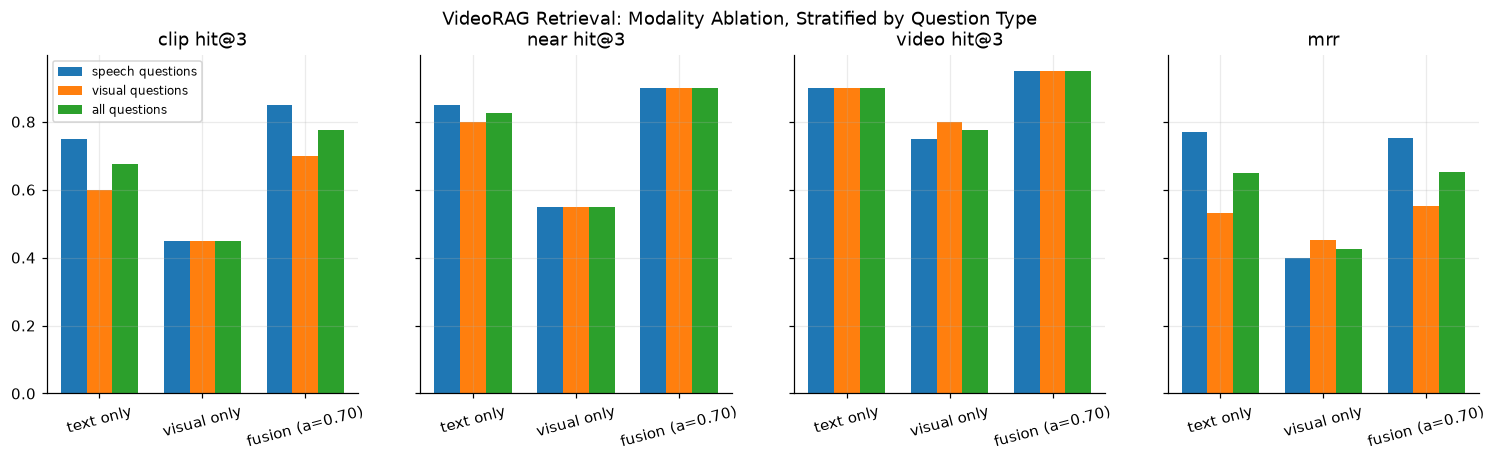

[saved] /cluster/home/m315832001/class/MMIP/week10/Outputs/Q3_video_retrieval_by_modality.png


In [39]:
Q3.plot_video_retrieval_by_modality(vsum, alpha_star);

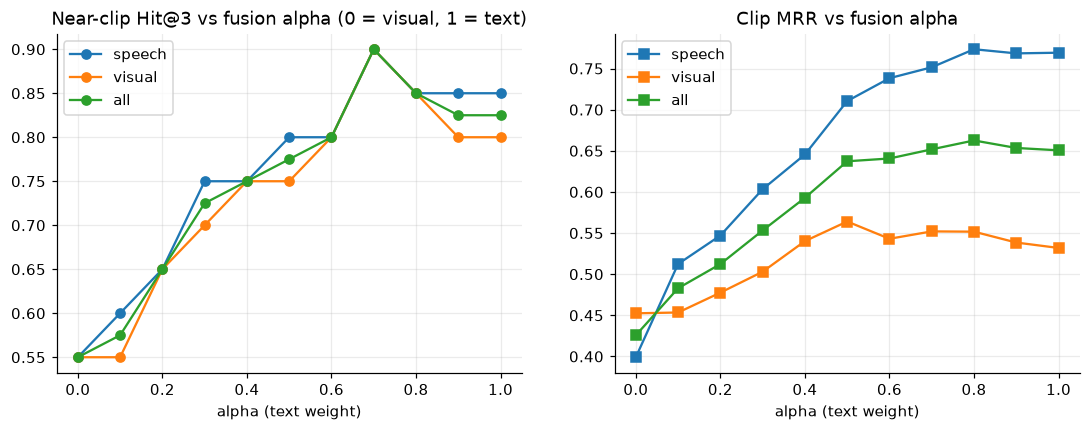

[saved] /cluster/home/m315832001/class/MMIP/week10/Outputs/Q3_video_alpha_sweep.png


In [40]:
Q3.plot_alpha_sweep(vsum);

**觀察**

* **Near Hit@3**（左）：三條線都在 α = 0 時最低（0.55），隨文字權重增加而上升，在 **α = 0.7 同時達到最高 0.90**，α → 1 再降到 0.80–0.85。
  兩種訊號都只用一種時都不是最好，確實互補。
* **MRR**（右）：speech 題隨 α 單調上升到約 0.77（α ≥ 0.8 持平），表示語音題的排序幾乎完全由逐字稿決定；
  visual 題在 **α = 0.5 達到最高（0.564）**，之後略降，表示視覺題需要文字與畫面各半。
* 所以最佳 α 取決於問題類型：語音題偏文字、視覺題偏均衡；α = 0.7 是兩者的折衷。若能先判斷問題模態，可以用不同的 α（query-dependent fusion）。

## Q3.B.3 生成評估：frames vs 文字消融、視覺 faithfulness、引用正確率

In [41]:
vgen = Q3.eval_video_generation(vlm, vindex, vqa[:30] if len(vqa) > 30 else vqa, alpha=alpha_star)
vgen.to_csv(OUT_DIR / "q3_video_generation_results.csv", index=False)
display(vgen.groupby(["gen_mode", "modality"])[["correctness", "faithfulness", "ref_hit", "retrieval_hit", "refused"]].mean().round(3))

[VideoGen] full done
[VideoGen] text_only done
[VideoGen] frames_only done


correctness  faithfulness  ref_hit  retrieval_hit  \
gen_mode    modality                                                      
frames_only speech           0.49         0.185     0.60            0.9   
            visual           0.44         0.000     0.50            0.9   
full        speech           0.63         0.250     0.70            0.9   
            visual           0.42         0.250     0.60            0.9   
text_only   speech           0.65         0.242     0.75            0.9   
            visual           0.46         0.000     0.50            0.9   

                      refused  
gen_mode    modality           
frames_only speech       0.15  
            visual       0.40  
full        speech       0.25  
            visual       0.60  
text_only   speech       0.25  
            visual       0.50

**觀察**

| 生成輸入 | speech 正確度 | speech 拒答率 | visual 正確度 | visual 拒答率 | visual faithfulness |
|---|---|---|---|---|---|
| frames + text（full） | 0.63 | 0.25 | 0.42 | 0.60 | **0.250** |
| text only | **0.65** | 0.25 | **0.46** | 0.50 | 0.000 |
| frames only | 0.49 | **0.15** | 0.44 | **0.40** | 0.000 |

* **speech 題文字最重要**：有逐字稿的 full / text only 正確度 0.63–0.65，只給畫面降到 0.49。
* **visual 題整體偏弱**（0.42–0.46），拒答率 40–60%；檢索命中率是 0.90，所以問題出在**生成端與題目品質**（「第三張圖片」這類指代讓模型對不上畫面）。
* **只有 full 模式的 visual 答案能被原始畫面驗證**（faithfulness 0.25，其他兩種都是 0）：同時給畫面與描述，模型的回答才會貼近畫面內容。
* 引用到正確 clip 的比例（ref_hit）speech 題 0.60–0.75、visual 題 0.50–0.60。
* 三種輸入在 n = 20 下差距不大，不宜過度解讀；但「speech 靠文字、visual 需要畫面」的方向與 Q3.B.2 的檢索結果一致。

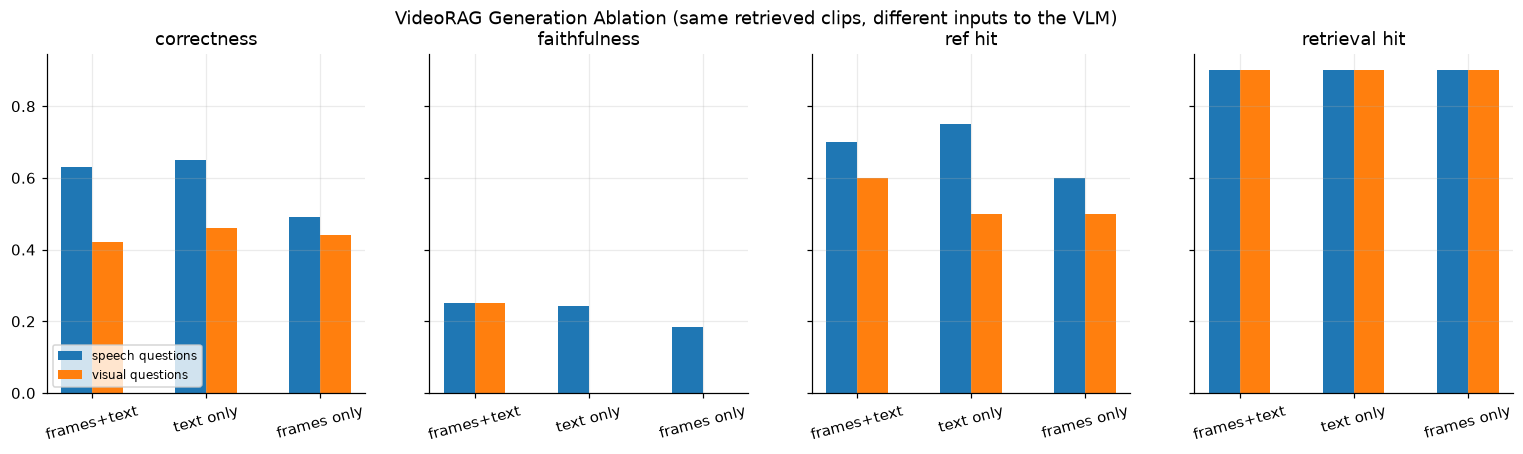

[saved] /cluster/home/m315832001/class/MMIP/week10/Outputs/Q3_video_generation_ablation.png


In [42]:
Q3.plot_video_generation(vgen);

## Q3.B.4 多輪 VideoRAG：查詢改寫消融

,near_hit,mrr
variant,,
history_concat,1.000,0.905
no_rewrite,0.286,0.265
oracle_standalone,0.714,0.592
vlm_rewrite,0.429,0.424


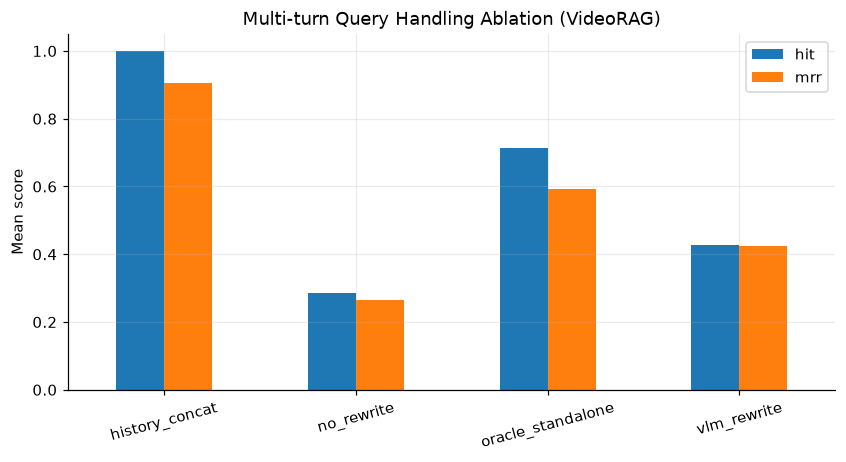

[saved] /cluster/home/m315832001/class/MMIP/week10/Outputs/Q3_video_multiturn_rewrite_ablation.png


In [43]:
vmt_df = Q3.eval_video_multiturn(vlm, vindex, vmt, alpha=alpha_star)
display(vmt_df.groupby("variant")[["near_hit", "mrr"]].mean().round(3))
Q3.plot_video_multiturn(vmt_df);

**觀察**

| 處理追問的方式 | Near Hit@3 | MRR |
|---|---|---|
| no_rewrite（直接用追問） | 0.286 | 0.265 |
| vlm_rewrite（VLM 改寫） | 0.429 | 0.424 |
| oracle_standalone（標準獨立問題） | 0.714 | 0.592 |
| **history_concat（歷史串接）** | **1.000** | **0.905** |

* 這次只保留了 **7 題**真正的代名詞追問：VLM 產生的追問有 73 次被判定不合格（追問與獨立問題一樣、或沒有指代），
  所以 n = 7（1 題 ≈ 0.14），**只能看趨勢**。
* 趨勢與文字 RAG 一致：直接用「那它下一步要按哪裡？」檢索幾乎找不到（0.29）；VLM 改寫有幫助（0.43）但離標準獨立問題（0.71）還很遠，
  **Qwen2.5-VL 的改寫能力明顯比文字 LLM 弱**。
* 歷史串接最高（1.00），因為 7 題都是同一支影片的追問、沒有換主題的情況，第一輪問答直接提供了影片關鍵字（與 Q3.A.3 同主題的結果一致）。
* 部分追問品質仍不理想（例如多題都是「那它下一步要按哪裡？」），擴充題數需要人工撰寫追問。

# Quiz 4 — GraphRAG
**論文**：*Attention Is All You Need* (arXiv:1706.03762)。
**流程**：PDF → chunk → LLM 抽取 entity / relation → 合併 → networkx 圖 → Louvain 社群 → 社群摘要。
**問答模式**：`naive`（向量 RAG 基準）/ `local`（實體為中心的子圖）/ `global`（社群摘要 map-reduce）/ `hybrid`（local + 向量片段）。
**Benchmark**：25 題（15 單點事實 / 6 多跳 / 4 全域摘要），位於 `Data/q4_benchmark.json`。
> 標準答案是依論文內容手寫；報告前請對照原文再確認一次，必要時直接修改 JSON。

## Q4.1 前處理：下載論文、抽文字、切塊

In [44]:
release(globals(), "ui2", "vchat", "vlm", "clip_model")
pdf = Q4.download_paper()
text = Q4.extract_paper_text(pdf)
p_chunks = Q4.chunk_paper(text, 1200, 150)
print(f"paper: {len(text):,} chars -> {len(p_chunks)} chunks")
print(p_chunks[3]["text"][:500])

[unload] ChineseCLIP ()
[GPU] after release torch-allocated 1.1 GB | device used 1.4 / 23.6 GB
paper: 29,826 chars -> 34 chunks
e, greatly improving results and massively accelerating our research.
†Work performed while at Google Brain. ‡Work performed while at Google Research.
31st Conference on Neural Information Processing Systems (NIPS 2017), Long Beach, CA, USA.
Recurrent neural networks, long short-term memory [13] and gated recurrent [7] neural networks in particular, have been firmly established as state of the art approaches in sequence modeling and transduction problems such as language modeling and machine tra


**觀察**

* 論文 PDF 共 29,826 字、切成 **34 個 chunk**。印出的第一段混入了頁尾註記（`†Work performed while at Google Brain…`、NIPS 2017 頁尾），
  代表 PDF 抽取有版面雜訊；下標符號也遺失（`d_model` → `dmodel`、`head_i` → `headi`），會影響之後的實體名稱。

## Q4.2 圖建構：LLM 實體/關係抽取 → 合併 → 圖

In [45]:
if "embedder" not in globals():
    embedder = Embedder()
llm = ChatLLM()
extractions = Q4.extract_graph_elements(llm, p_chunks)
G = Q4.build_graph(extractions, embedder, merge_thr=0.92)
display(pd.DataFrame([{"entity": d["name"], "type": d["type"], "degree": G.degree(n), "desc": d["descs"][0] if d["descs"] else ""}
                      for n, d in G.nodes(data=True)]).sort_values("degree", ascending=False).head(15))

Loading weights:   0%|          | 0/339 [00:00<?, ?it/s]

[merge] merged 11 near-duplicate entities (see Data/q4_merge_log.json)
[graph] 155 nodes / 163 edges


,entity,type,degree,desc
5,Transformer,MODEL,25,A new simple network architecture based solely on attention mechanisms.
49,headi,COMPONENT,13,"Each individual attention head computed in parallel on the projected queries, keys, and values."
98,base model,MODEL,11,models with standard hyperparameters
26,Self-Attention,METHOD,9,An attention mechanism relating different positions of a single sequence in order to compute a representation of the...
134,WSJ,DATASET,8,The Wall Street Journal dataset
35,dmodel,HYPERPARAMETER,8,"dimension of the model's output, set to 512"
25,Multi-Head Attention,COMPONENT,8,A method used to counteract the effect of averaging attention-weighted positions in the Transformer model.
28,decoder,COMPONENT,7,A component that generates an output sequence one element at a time based on the encoder's output.
27,encoder,COMPONENT,6,A component that maps an input sequence to a sequence of continuous representations.
73,positional encoding,METHOD,6,A method to add positional information to the input embeddings in a transformer model.


**觀察**

* 抽出 **155 個實體、163 條關係**，合併了 11 組近似重複的實體。邊數 ≈ 點數（平均度約 2），圖相當稀疏。
* 度數最高的是 `Transformer`（25），其次是 `headi`、`base model`、`Self-Attention`、`WSJ`、`dmodel`、`Multi-Head Attention`…
* ⚠️ 雜訊實體：`headi`、`dmodel`、`Table 3`、`base model` 等是 PDF 抽取遺失下標與 LLM 把表格/段落當實體造成，
  下一步可加 PDF 後處理（還原下標）與實體白名單改善圖品質。

## Q4.3 社群偵測與社群摘要

In [46]:
comms = Q4.detect_communities(G)
summ = Q4.summarize_communities(llm, G, comms)
for s in summ[:3]:
    print(f"--- community {s['community']} (size {s['size']}) ---\n{s['summary']}\n")

[community] 28 communities; sizes = [23, 18, 15, 12, 11, 11, 10, 8, 5, 5, 5, 4, 4, 3, 3, 2, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1]
--- community 0 (size 23) ---
The Transformer model, based solely on attention mechanisms, uses learned positional embeddings and sinusoidal positional encoding to add positional information. It evaluates on Sections 22 and 23 of the WSJ dataset and performs well in semi-supervised settings. The model uses a beam size of 21 and achieves new state-of-the-art results on WMT 2014 English-to-French and English-to-German translation tasks, outperforming models like the Recall Neural Network Grammar and Berkeley Parser. The Transformer improves translation quality and sets α to 0.3, using TensorFlow for training and evaluation.

--- community 1 (size 18) ---
In the "Attention Is All You Need" paper, **Multi-Head Attention** (MHA) uses **queries**, **keys**, and **values** which are linearly projected h times with different learned linear projections. Each of the h *

**觀察**

* Louvain 切出 **28 個社群**，大小 `[23, 18, 15, 12, 11, 11, 10, 8, 5, 5, …]`，其中 **8 個是只有 1 個節點的孤立社群**，圖過度碎片化。
* 圖不連通是主因：許多社群本身就是獨立的小連通元件。大型社群語意清楚：社群 0 = 位置編碼 + WSJ/WMT 實驗結果；社群 1 = Multi-Head Attention 的 Q/K/V、h、d_k、d_v、softmax。
  這是 global search 能使用的「主題摘要」，但碎片太多會稀釋 map-reduce 的答案品質。

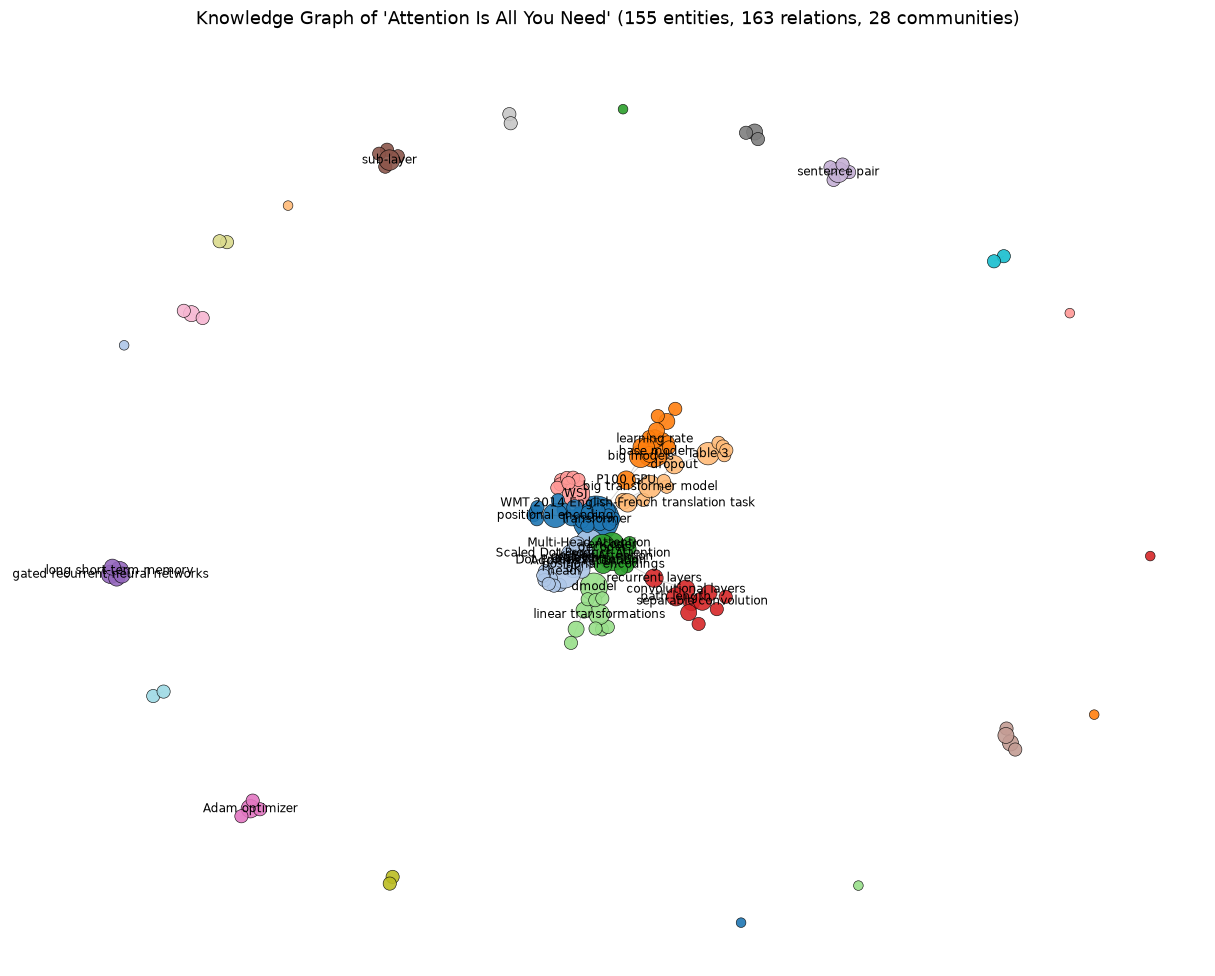

[saved] /cluster/home/m315832001/class/MMIP/week10/Outputs/Q4_graph_overview.png


In [47]:
Q4.plot_graph_overview(G, comms);

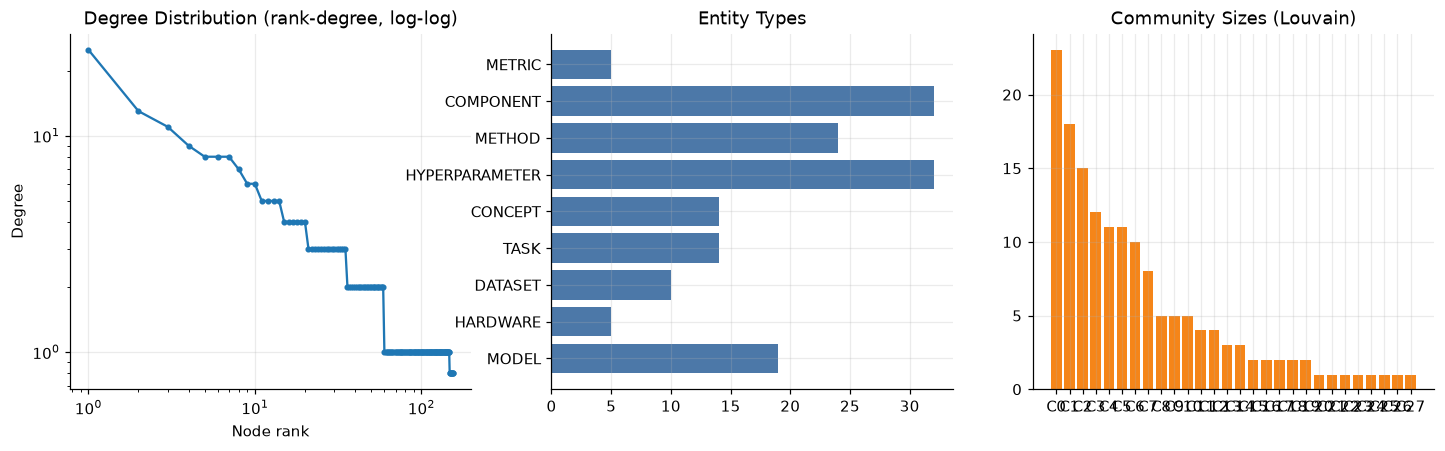

[saved] /cluster/home/m315832001/class/MMIP/week10/Outputs/Q4_graph_statistics.png


In [48]:
Q4.plot_graph_statistics(G, comms);

**觀察**

* 總覽圖：中央有一個互相連通的主群（`Transformer`、Multi-Head Attention、positional encoding、WSJ、WMT 2014 等，標籤彼此重疊看不清），
  **其餘約二十個小群散落在四周、與主群沒有連線**（例如 LSTM / gated recurrent networks、Adam optimizer、sentence pair、sub-layer）——
  圖是不連通的，這也解釋了為什麼 Louvain 會切出許多小社群與孤立點。
* 統計圖：度數分佈是長尾（最高約 25，約 95 個節點度數只有 1）；實體型態以 **COMPONENT 與 HYPERPARAMETER（各約 32）** 最多，其次 METHOD（24）、MODEL（19）；
  METRIC / HARDWARE 各只有約 5 個；社群大小從 23 一路遞減到 1。

## Q4.4 建立 GraphRAG 並儲存圖與 embedding

In [49]:
chunk_emb = embedder.encode([c["text"] for c in p_chunks])
rag = Q4.GraphRAG(llm, embedder, p_chunks, chunk_emb, G, summ)
Q4.save_graph(G, [s["nodes"] for s in summ], rag.node_emb, chunk_emb, p_chunks)

[saved] q4_graph.json / q4_graph.graphml / q4_embeddings.npz / q4_chunks.json in /cluster/home/m315832001/class/MMIP/week10/Outputs


## Q4.5 範例：同一個多跳問題，四種模式的答案比較

Q: How is the per-head dimension d_k of the base model determined from other hyperparameters, and what is its value? 
GOLD: d_k = d_v = d_model / h = 512 / 8 = 64. 

[naive] (2.6s, ctx 4466 chars)
The per-head dimension \( d_k \) is determined by dividing the model's embedding dimension \( d_{\text{model}} \) by the number of attention heads \( h \). Given \( d_{\text{model}} = 512 \) and \( h = 8 \), the per-head dimension \( d_k \) is calculated as \( d_k = \frac{d_{\text{model}}}{h} = \frac{512}{8} = 64 \).

[local] (1.8s, ctx 7871 chars)
The per-head dimension dk of the base model is determined by the formula dk = dv = dmodel/h, where dmodel is 512 and h (the number of attention heads) is 8. Therefore, the value of dk for the base model is 64.

[global] (10.8s, ctx 2671 chars)
For the base model in the 'Attention Is All You Need' paper, the per-head dimension \( d_k \) is typically 64, given that the total embedding dimension \( d_{model} \) is 512 and there are 8 attention heads. 

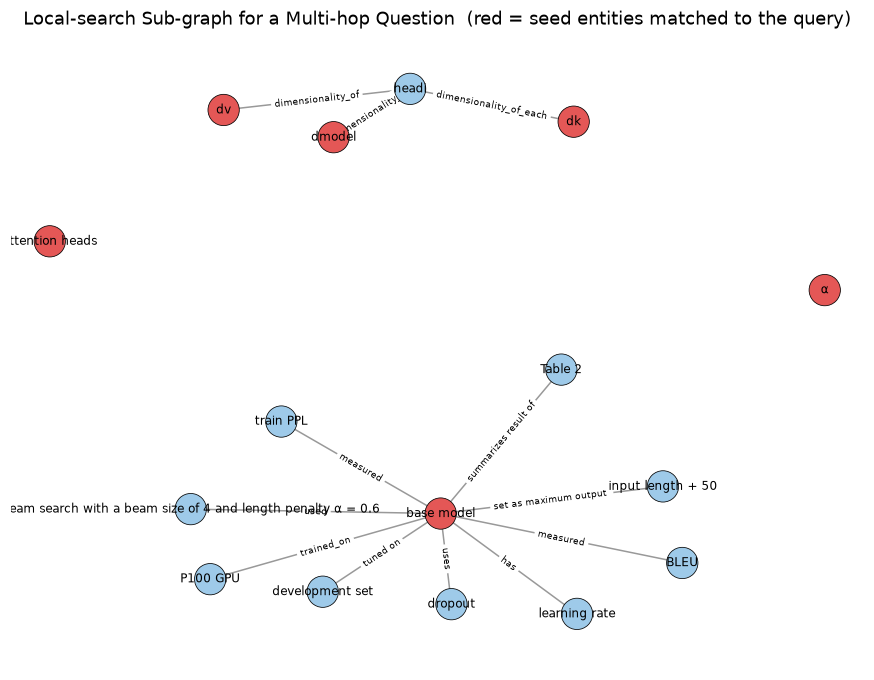

[saved] /cluster/home/m315832001/class/MMIP/week10/Outputs/Q4_local_search_subgraph.png


In [50]:
bench = Q4.load_benchmark()
q = next(b for b in bench if b["category"] == "multi")
print("Q:", q["question"], "\nGOLD:", q["answer"], "\n")
for m in Q4.METHODS:
    r = rag.answer(m, q["question"])
    print(f"[{m}] ({r['latency']:.1f}s, ctx {len(r['context'])} chars)\n{r['answer']}\n")
r = rag.local(q["question"])
Q4.plot_subgraph(G, r["nodes"], r["seeds"], "Local-search Sub-graph for a Multi-hop Question");

**觀察**

* 同一個多跳問題（d_k 怎麼由其他超參數決定？標準答案 d_k = d_model / h = 512 / 8 = 64）：
  naive / local / hybrid 都正確答出 64，**global 反而答得含糊**（「without specific values… cannot be determined」），而且要 10.8 秒（其他 1.8–2.7 秒）。
* local 的答案出現 `dk`、`dmodel`（沒有下標），是 PDF 抽取遺失下標的連帶影響。
* 子圖圖中紅點 = 與問題匹配的種子實體，周圍是它們的鄰居，可看到 `d_model`、`h`、`d_k` 之間的關係邊。

## Q4.6 Benchmark 評估（25 題 × 4 種模式）

[bench] naive done (avg 1.3s)
[bench] local done (avg 1.4s)
[bench] global done (avg 8.4s)
[bench] hybrid done (avg 1.9s)


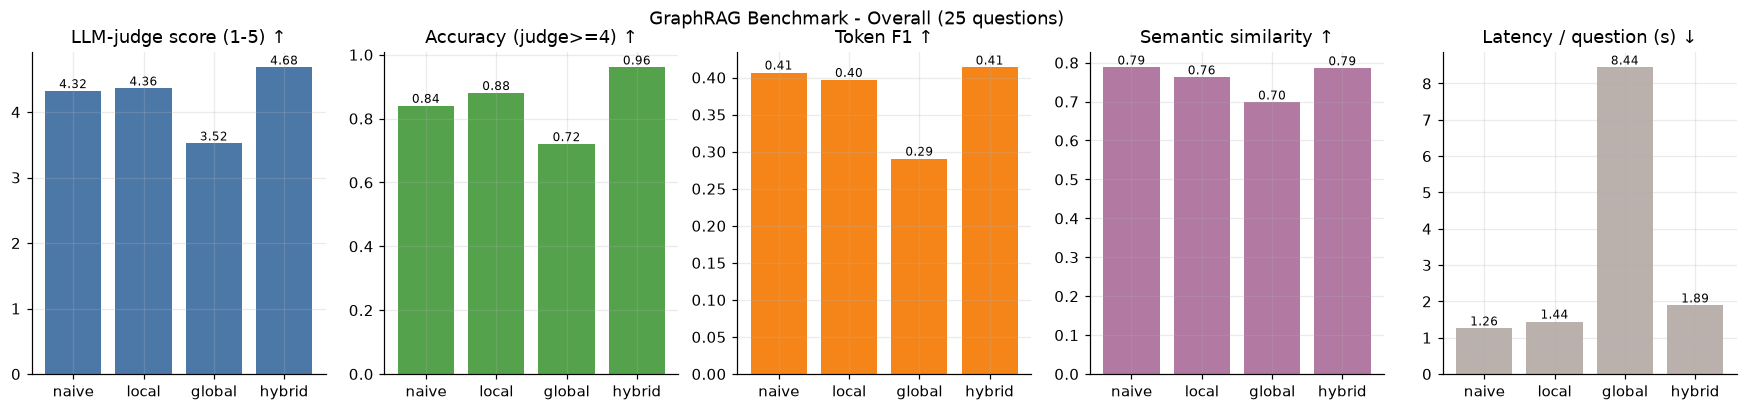

[saved] /cluster/home/m315832001/class/MMIP/week10/Outputs/Q4_benchmark_overall.png


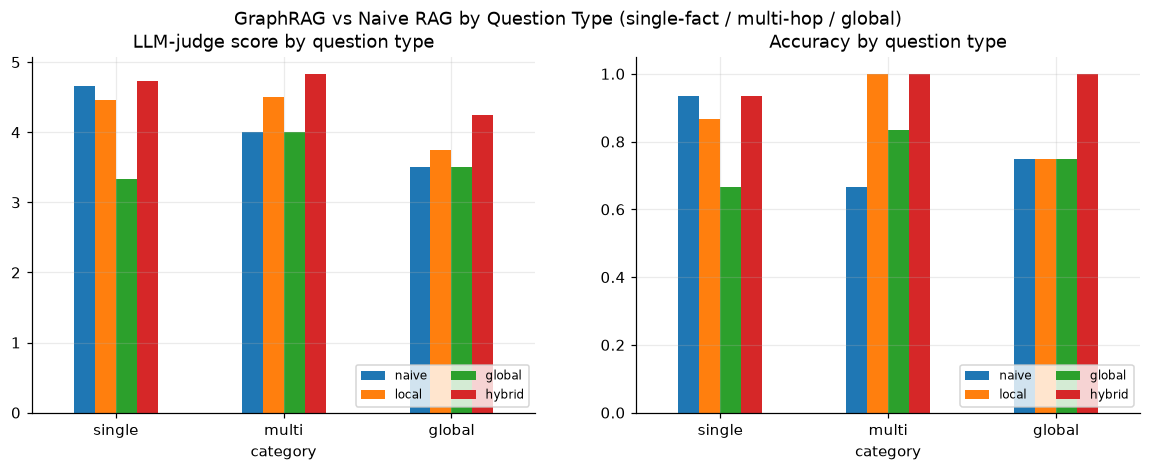

[saved] /cluster/home/m315832001/class/MMIP/week10/Outputs/Q4_benchmark_by_category.png


,judge,correct,f1,sem,lat
method,,,,,
naive,4.32,0.84,0.407,0.788,1.256
local,4.36,0.88,0.397,0.762,1.445
global,3.52,0.72,0.291,0.698,8.440
hybrid,4.68,0.96,0.414,0.786,1.889


In [51]:
res = Q4.evaluate_graphrag(rag, bench)
res.to_csv(OUT_DIR / "q4_benchmark_results.csv", index=False)
summary4 = Q4.plot_benchmark(res)
display(summary4.round(3))

**觀察**

| 模式 | judge(1–5) | 準確率(judge ≥ 4) | token F1 | 語意相似 | 延遲(秒/題) |
|---|---|---|---|---|---|
| naive（向量 RAG） | 4.32 | 0.84 | 0.407 | **0.788** | **1.26** |
| local | 4.36 | 0.88 | 0.397 | 0.762 | 1.45 |
| global | 3.52 | 0.72 | 0.291 | 0.698 | 8.44 |
| **hybrid（local + 向量片段）** | **4.68** | **0.96** | **0.414** | 0.786 | 1.89 |

* **hybrid 最好**：25 題答對 24 題（準確率 0.96，比 naive 高 12 個百分點），延遲只多約 0.6 秒。
* local 與 naive 的平均 judge 相近（4.36 vs 4.32），準確率略高（0.88 vs 0.84）。
* **global 最差且最慢**（約 naive 的 6.7 倍），不適合用來回答具體事實題。

In [52]:
display(res.pivot_table(index='category', columns='method', values='judge', aggfunc='mean').round(2))

method,global,hybrid,local,naive
category,,,,
global,3.50,4.25,3.75,3.50
multi,4.00,4.83,4.50,4.00
single,3.33,4.73,4.47,4.67


**觀察**

各題型的 judge 平均分：

| 題型 | naive | local | global | hybrid |
|---|---|---|---|---|
| single（15 題） | 4.67 | 4.47 | 3.33 | **4.73** |
| multi（6 題多跳） | 4.00 | 4.50 | 4.00 | **4.83** |
| global（4 題全域） | 3.50 | 3.75 | 3.50 | **4.25** |

* **多跳題圖譜有明顯幫助**：local / hybrid 比 naive 高 0.50 / 0.83 分，這是 GraphRAG 的主要價值（關係邊把分散在不同 chunk 的資訊串起來）。
* **單點事實題 naive 已經很強**（4.67），local 反而較低（4.47），因為細節數值不一定被抽成實體，子圖 context 也夾雜較多無關內容；hybrid 補上原文片段後最好（4.73）。
* **全域摘要題 global 模式沒有贏**（3.50，與 naive 相同，低於 hybrid 4.25），原因是社群過度碎片化（28 個，8 個孤立）+ 7B 模型 map-reduce 品質有限。
* 限制：只有 25 題（1 題 ≈ 0.04 準確率）、judge 與生成同為 Qwen2.5-7B（自評偏誤）、全域題只有 4 題，差異小的比較不宜過度推論。

### 錯誤分析：local 模式答錯 (judge ≤ 2) 的題目

In [53]:
bad = res[(res.method == "local") & (res.judge <= 2)].merge(pd.DataFrame(bench)[["id", "question", "answer"]], left_on="qid", right_on="id", suffixes=("_pred", "_gold"))
display(bad[["category", "question", "answer_gold", "answer_pred", "judge"]])

,category,question,answer_gold,answer_pred,judge
0,single,What kind of positional encoding does the Transformer use?,Sinusoidal positional encodings: sine and cosine functions of different frequencies.,"The Transformer uses learned positional embeddings for positional information, replacing the original sinusoidal pos...",1.0
1,single,What label smoothing value was employed during training?,"Label smoothing with epsilon_ls = 0.1, which hurts perplexity but improves accuracy and BLEU.",The context provided does not mention any label smoothing value; it only discusses other hyperparameters such as lea...,1.0
2,global,Summarize the main contribution of the paper and its key experimental results.,"It proposes the Transformer, a sequence transduction model based solely on attention that dispenses with recurrence ...","The paper evaluates various methods on the WSJ dataset, which comprises 40K sentences from the Wall Street Journal. ...",2.0


**觀察**

local 模式只有 3 題 judge ≤ 2，都反映「只看圖」的缺點：
1. **位置編碼**（judge 1）：模型答「learned positional embeddings 取代了 sinusoidal」，但論文採用 sinusoidal。論文 Table 3 有比較 learned 版本，
   抽取時卻變成與 Transformer 相連的關係，社群 0 的摘要也寫成「uses learned positional embeddings」→ **圖中的錯誤關係直接誤導了回答**。
2. **Label smoothing 值**（judge 1）：回答「context 沒有提到」——`ε_ls = 0.1` 沒有被抽成實體或關係，子圖裡找不到 → **圖譜漏抽**。
3. **總結主要貢獻與結果**（judge 2）：種子實體落在 WSJ 相關節點，回答偏向句法分析實驗，沒有涵蓋主要的翻譯結果 → **全域題不適合 local 模式**。
→ hybrid 補上原文片段後前兩類細節題就能答對；改進方向：PDF 後處理（還原下標）、讓 hybrid 成為預設，以及依題型路由（router）。

# 輸出檔案總覽（`Outputs/`）
* 圖片：`Q1_*.png` … `Q4_*.png`
* 模型 / 索引：`q1_index.npz`+`q1_index_chunks.json`、`q1_best_config.json`、`q2_videorag_index.npz`+`q2_videorag_index_clips.json`、
  `q4_graph.json`、`q4_graph.graphml`、`q4_embeddings.npz`、`q4_chunks.json`
* 實驗結果表：`q1_grid_summary.csv`、`q1_prompting_results.csv`、`q3_*.csv`、`q4_benchmark_results.csv`

---
# 總結與已知限制

| Quiz | 主要結果 |
|---|---|
| Q1 | 29 篇繁中維基 → 最終 1,363 個 chunk（≥200）；最佳設定 chunk 150 / overlap 50 / Top-K 8（各 chunk size 排序品質相近，context 成本決定勝負）；最佳 Prompting = `grounded_strict`（judge 4.70、引用 100%、語料外題拒答 100%，zero-shot 僅 42%） |
| Q2 | 10 支影片 → 68 clip；ASR（whisper-large-v3-turbo）+ VLM caption ⊕ Chinese-CLIP 雙索引的多輪 VideoRAG，4 輪 demo 全部找到正確影片並附時間戳引用 |
| Q3-A | RAGAS-style：Hit 1.00、MRR 0.73、faithfulness 0.86、answer relevancy 0.76（最弱）、correctness 0.90；多輪：LLM 改寫整體 Hit 0.868 最高，歷史串接在換主題時崩潰（0.25） |
| Q3-B | 40 題（speech 20 / visual 20）：fusion(α=0.7) Near Hit@3 0.90 > text 0.825 > visual 0.55；speech 題靠文字、visual 題融合幫助最大；生成端 visual 題拒答率 40–60% |
| Q4 | 155 節點 / 163 邊 / 28 社群；hybrid 準確率 0.96 > local 0.88 > naive 0.84 > global 0.72；多跳題圖譜優勢最明顯 |

**已知限制（寫報告時請如實說明）**
1. 所有 LLM-judge 皆由生成用的同一個 Qwen2.5-7B 擔任，可能偏高；QA 與影片題目都是 LLM / VLM 產生的 silver label。
2. Quiz 2 的影片是網路教學影片，不是自行錄製；faster-whisper 因 CUDA 版本不符改用 transformers Whisper。
3. 影片 benchmark 部分題目含「第三張圖片」「這個公式」等指代；影片多輪題只有 7 題（VLM 很難產生合格的代名詞追問）。
4. Q4 圖譜因 PDF 抽取遺失下標（`dmodel`、`headi`）、出現錯誤關係（learned vs sinusoidal positional encoding），社群過度碎片化。
5. 樣本數小（Q1 端到端 60 題、Q3-B 每種模態 20 題、Q4 25 題），小幅差異不具統計顯著性。